# GLBL 570 · Week 8 — Spatial Analysis for Global Studies: Companion Notebook

Week 7 asked **"what is where?"** This week the map becomes an **instrument**: combine layers, measure distance, test whether a pattern is real, and let a model infer the ground from space. Each section follows a chapter of `GLBL570_Week8_Spatial_Analysis_v3.pptx` and writes the figures the deck's `[FIGURE SLOT]` notes name.

| § | Chapter | LO | Deck slides | Figures written to `outputs/` |
|---|---|---|---|---|
| 0 | Setup and the data pack | — | — | — |
| 1 | From mapping to analysis | — | 7–10 | `spatial_shuffle_test.png` (10) |
| 2 | Overlay analysis | **1** | 11–14 | `overlay_operations.png` (13) · `overlay_policy_forest_protected.png` (14) |
| 3 | Buffer, distance and proximity | **1** | 15–21 | `distance_to_water_development.png` (18) · `proximity_toolbox.png` (19) · `buffer_sensitivity.png` (20) · `data_preprocessing_dissolve_integrate.png` (21) |
| 4 | Patterns, clusters and hotspots | **2** | 22–29 | `clusters_moran_lisa.png` (25) · `hotspots_getis_ord.png` (26) · `point_pattern_nn.png` (27) · `spatial_correlation_two_variables.png` (29) |
| 5 | Remote sensing and machine learning | **3** | 30–37 | `rs_ndvi_classification.png` (32) · `ml_confusion_matrix.png` (36) |
| 6 | Policy and the politics of categories | **4** | 38–43 | `categories_forest_definitions.png` (40) · `maup_two_aggregations.png` (41) · `ethics_point_vs_aggregated.png` (43) |
| 7 | Discussion and AI engagement | — | 44–46 | — |
| 8 | Lab and deliverable | **5** | 47–49 | memo template, QGIS layers, figure checklist |

**One continuous case.** §§2–4 work in the **Pacific Northwest**: the overlay, distance and preprocessing steps in a six-county focus area around **Mount Hood and the Columbia River Gorge** (forest + protected land + a large river + Portland), and the cluster statistics on all **Oregon, Washington and Idaho** counties, which contain the focus area. The humanitarian buffer/proximity track (§3.2) uses the **Rohingya refugee camps of Cox's Bazar** and UCDP conflict events.

**Every analytical section ends with a line beginning `CANNOT ESTABLISH:`** — what the result does not show. Spatial analysis does not remove analytical choices; it makes them consequential.

Run from the repository root (it needs `lab_data/` and `lab_data_week8/`). CPU only, no internet. Needs `scikit-learn` (§5) in addition to the Week 7 libraries.

In [1]:
import os, warnings
from pathlib import Path

import sys
import pyproj
if pyproj.datadir.get_data_dir().startswith(sys.prefix):         # conda: pyproj and GDAL share one PROJ install
    os.environ.setdefault("PROJ_DATA", pyproj.datadir.get_data_dir())   # tell GDAL where proj.db is
warnings.filterwarnings("ignore", message="Numba not installed")
warnings.filterwarnings("ignore", message="Setting the shape on a NumPy array")   # raised inside rasterio on NumPy >= 2.5

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import rasterio
from rasterio import features
from rasterio.plot import plotting_extent
from scipy import ndimage, sparse, stats
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

LAB, LAB8 = Path("lab_data"), Path("lab_data_week8")
assert LAB.exists() and LAB8.exists(), "Run from the repository root: lab_data/ and lab_data_week8/ must be next to this notebook."
VEC, TAB, RAS = LAB / "vector", LAB / "tables", LAB / "raster"            # Week 7 pack
VEC8, TAB8, RAS8 = LAB8 / "vector", LAB8 / "tables", LAB8 / "raster"      # Week 8 additions
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RNG = np.random.default_rng(570)
ALBERS = 5070                     # NAD83 / Conus Albers: equal-area, metres — all U.S. analysis happens here

PAL = {"blue": "#065A82", "teal": "#1C7293", "green": "#2A7F62", "purple": "#6B5B95", "amber": "#B9791F",
       "terra": "#C05746", "ink": "#25313C", "muted": "#5B6B7A"}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "figure.facecolor": "white", "savefig.bbox": "tight",
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink"], "axes.edgecolor": PAL["muted"],
    "xtick.color": PAL["muted"], "ytick.color": PAL["muted"], "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})


def ramp(*colours):
    return LinearSegmentedColormap.from_list("", colours)


SEQ_BLUE, SEQ_GREEN, SEQ_TERRA = ramp("#EEF4F8", PAL["blue"]), ramp("#F1F7F4", PAL["green"]), ramp("#FBF1EE", PAL["terra"])
DIVERGING = ramp(PAL["blue"], "#F2F2F2", PAL["terra"])
MISSING = {"color": "#D9D9D9", "hatch": "////", "edgecolor": "#9A9A9A", "label": "no data"}
FIGS = {}                         # figure file -> deck slide, filled by save()


def source(fig, text):
    fig.text(0.01, -0.01, "Source: " + text, fontsize=6, color=PAL["muted"], ha="left", va="top")


def save(fig, name, slide, pdf=False):
    fig.savefig(OUT / name, dpi=220, bbox_inches="tight", facecolor="white")
    if pdf:
        fig.savefig(OUT / Path(name).with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    FIGS[name] = slide
    plt.show()


def cannot(text):
    print("CANNOT ESTABLISH:", text)


def polygons_only(gdf):
    # make_valid can return GeometryCollections; keep the polygonal parts, one row per input feature
    g = gdf.copy(); g["geometry"] = g.make_valid(); g["_row"] = np.arange(len(g))
    g = g.explode(index_parts=False); g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])]
    return g.dissolve(by="_row", as_index=False).drop(columns="_row")


print("geopandas", gpd.__version__, "| shapely", shapely.__version__, "| rasterio", rasterio.__version__)

geopandas 1.0.1 | shapely 2.0.2 | rasterio 1.3.8


### 0.1 The data pack
`lab_data/` is the Week 7 pack (unchanged). `lab_data_week8/` adds the layers the syllabus tasks need; `lab_data_week8/README.md` lists source, licence, CRS and pitfalls for each.

In [2]:
HOW = {".shp": "drag & drop (vector)", ".tif": "drag & drop (raster)", ".csv": "Add Delimited Text Layer"}
inv = [{"file": str(p), "MB": round(p.stat().st_size / 1e6, 2), "QGIS": HOW[p.suffix]}
       for p in sorted(LAB8.rglob("*")) if p.suffix in HOW]
inv += [{"file": str(VEC / f), "MB": round((VEC / f).stat().st_size / 1e6, 2), "QGIS": HOW[".shp"]}
        for f in ["us_counties_acs2022.shp", "usgs_earthquakes_2025_m25.shp", "world_countries_ne110m.shp"]]
inv += [{"file": str(RAS / f), "MB": round((RAS / f).stat().st_size / 1e6, 2), "QGIS": HOW[".tif"]}
        for f in ["champaign_sentinel2_2023_10m.tif", "illinois_landcover_nlcd2021_150m.tif"]]
display(pd.DataFrame(inv))

,file,MB,QGIS
0,lab_data_week8/raster/focus_nlcd2021_30m.tif,3.85,drag & drop (raster)
1,lab_data_week8/raster/focus_srtm_90m.tif,3.29,drag & drop (raster)
2,lab_data_week8/raster/nlcd_classes.csv,0.00,Add Delimited Text Layer
3,lab_data_week8/tables/ucdp_ged_2023_near_camps...,0.06,Add Delimited Text Layer
4,lab_data_week8/vector/coxsbazar_camps_2023.shp,0.18,drag & drop (vector)
5,lab_data_week8/vector/focus_counties_pnw.shp,0.01,drag & drop (vector)
6,lab_data_week8/vector/padus41_mthood_gorge.shp,1.46,drag & drop (vector)
7,lab_data/vector/us_counties_acs2022.shp,3.78,drag & drop (vector)
8,lab_data/vector/usgs_earthquakes_2025_m25.shp,0.14,drag & drop (vector)
9,lab_data/vector/world_countries_ne110m.shp,0.18,drag & drop (vector)


---
## 1 · From Mapping to Analysis  (slides 7–10)
Week 7's county map was a **description**: one layer answering *what is where*. Analysis asks what locations mean **together** (slide 8). Slide 10's test for whether an analysis is *spatial*: **when the location changes, does the information content change?** The cell below runs that test directly: it shuffles which county holds which poverty rate and compares a non-spatial summary (a histogram) with a spatial one (each county against its neighbours) before and after.

The data are the **3,100-odd counties of the contiguous United States** (the lower 48 states and DC). The neighbour relation is built once here and reused in §4.

Counties without a neighbour (dropped): ['Nantucket County', 'San Juan County']
Contiguous U.S.: 3,107 counties (48 states + DC), mean 5.8 neighbours


real r = 0.673; one shuffle r = 0.029; 999 shuffles: mean -0.000, middle 95% -0.05 to 0.05, max 0.08; 0 shuffles reach r >= 0.67


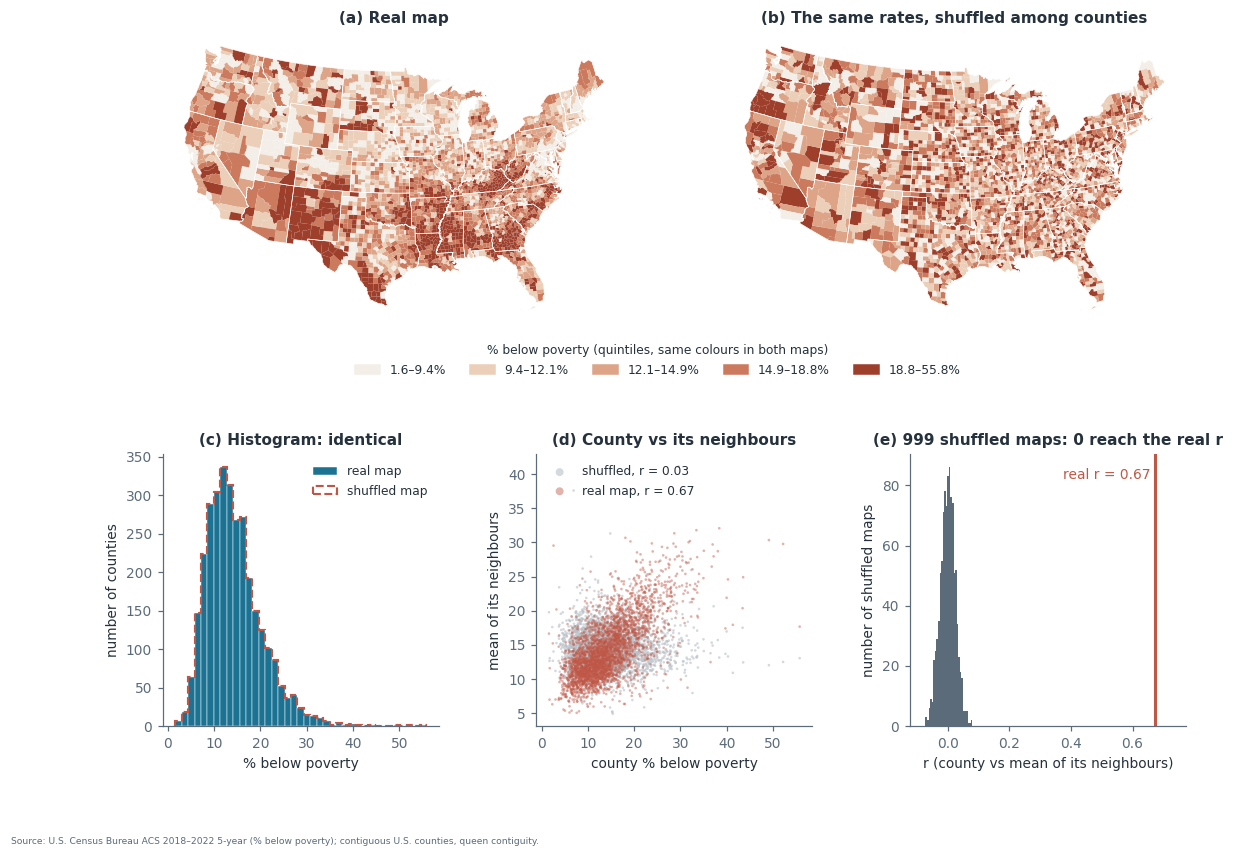

In [3]:
FIELDS = pd.read_csv(VEC / "us_counties_acs2022_field_dictionary.csv")
counties = gpd.read_file(VEC / "us_counties_acs2022.shp").rename(columns=dict(zip(FIELDS.shapefile_field, FIELDS.acs_field)))
pnw = counties[counties.state_abbr.isin(["OR", "WA", "ID"])].to_crs(ALBERS).reset_index(drop=True)   # study region of §4.4
us48 = counties[~counties.state_abbr.isin(["AK", "HI", "PR"])].to_crs(ALBERS).reset_index(drop=True)

nb = gpd.sjoin(us48[["geometry"]], us48[["geometry"]], predicate="intersects")    # queen contiguity
nb = nb[nb.index != nb.index_right]
islands = sorted(set(us48.index) - set(nb.index))
print("Counties without a neighbour (dropped):", us48.loc[islands, "county_label"].tolist())
keep = np.setdiff1d(us48.index, islands)
R = us48.loc[keep].reset_index(drop=True)
remap = {old: new for new, old in enumerate(keep)}
i, j = nb.index.map(remap), nb.index_right.map(remap)
ok = ~(pd.isna(i) | pd.isna(j))
Wb = sparse.csr_matrix((np.ones(ok.sum()), (np.asarray(i[ok], int), np.asarray(j[ok], int))), shape=(len(R),) * 2)
kdeg = np.asarray(Wb.sum(axis=1)).ravel()
W = sparse.diags(1 / kdeg) @ Wb                                                  # row-standardised
assert R.poverty_pct.notna().all()
print(f"Contiguous U.S.: {len(R):,} counties (48 states + DC), mean {kdeg.mean():.1f} neighbours")
STATE_LINES = R.dissolve("state_abbr").boundary

x = R.poverty_pct.values
lag = W @ x
r_obs = np.corrcoef(x, lag)[0, 1]

# The shuffle test (slide 10): hand the same rates to the counties in random order
shuf = np.random.default_rng(11)                  # own generator, so the permutations in §4 are unchanged
xs = shuf.permutation(x)
lag_s = W @ xs
r_one = np.corrcoef(xs, lag_s)[0, 1]
r_null = np.array([np.corrcoef(v, W @ v)[0, 1] for v in (shuf.permutation(x) for _ in range(999))])
n_ge = int((r_null >= r_obs).sum())

POV_BINS = np.percentile(x, [0, 20, 40, 60, 80, 100])           # quintiles, shared by both maps
POV_COLS = ["#F3EFE8", "#EBCFB9", "#DDA488", "#CB7A5E", "#9E3F2C"]
fig = plt.figure(figsize=(12, 8.4))
gs = fig.add_gridspec(2, 6, height_ratios=[1.2, 1], hspace=0.38, wspace=1.1)
for k, (vals, ttl) in enumerate([(x, "(a) Real map"), (xs, "(b) The same rates, shuffled among counties")]):
    ax = fig.add_subplot(gs[0, 3 * k:3 * k + 3])
    cls = np.clip(np.searchsorted(POV_BINS, vals, side="right") - 1, 0, 4)
    R.plot(ax=ax, color=[POV_COLS[c] for c in cls], edgecolor="none")
    STATE_LINES.plot(ax=ax, color="white", lw=0.4)
    ax.set_title(ttl); ax.set_axis_off()
fig.legend([Patch(color=c) for c in POV_COLS],
           [f"{lo:.1f}–{hi:.1f}%" for lo, hi in zip(POV_BINS[:-1], POV_BINS[1:])],
           loc="upper center", bbox_to_anchor=(0.5, 0.535), ncol=5, fontsize=8, frameon=False,
           title="% below poverty (quintiles, same colours in both maps)", title_fontsize=8)
a1, a2, a3 = (fig.add_subplot(gs[1, 2 * k:2 * k + 2]) for k in range(3))
bins = np.linspace(x.min(), x.max(), 40)
a1.hist(x, bins=bins, color=PAL["teal"], edgecolor="white", lw=0.3, label="real map")
a1.hist(xs, bins=bins, histtype="step", color=PAL["terra"], lw=1.4, ls="--", label="shuffled map")
a1.set_xlabel("% below poverty"); a1.set_ylabel("number of counties"); a1.legend(frameon=False, fontsize=8)
a1.set_title("(c) Histogram: identical")
a2.scatter(xs, lag_s, s=3, color="#B9C0C7", alpha=0.6, edgecolor="none", label=f"shuffled, r = {r_one:.2f}")
a2.scatter(x, lag, s=3, color=PAL["terra"], alpha=0.45, edgecolor="none", label=f"real map, r = {r_obs:.2f}")
a2.set_xlabel("county % below poverty"); a2.set_ylabel("mean of its neighbours")
a2.legend(frameon=False, fontsize=8, markerscale=3, loc="upper left"); a2.set_title("(d) County vs its neighbours")
a3.hist(r_null, bins=30, color=PAL["muted"], edgecolor="none")
a3.axvline(r_obs, color=PAL["terra"], lw=2)
a3.set_xlim(min(r_null.min(), 0) - 0.05, r_obs + 0.1)
a3.text(r_obs, a3.get_ylim()[1] * 0.95, f"real r = {r_obs:.2f} ", color=PAL["terra"], ha="right", va="top", fontsize=9)
a3.set_xlabel("r (county vs mean of its neighbours)"); a3.set_ylabel("number of shuffled maps")
a3.set_title(f"(e) 999 shuffled maps: {n_ge} reach the real r")
source(fig, "U.S. Census Bureau ACS 2018–2022 5-year (% below poverty); contiguous U.S. counties, queen contiguity.")
print(f"real r = {r_obs:.3f}; one shuffle r = {r_one:.3f}; 999 shuffles: mean {r_null.mean():.3f}, "
      f"middle 95% {np.percentile(r_null, 2.5):.2f} to {np.percentile(r_null, 97.5):.2f}, max {r_null.max():.2f}; "
      f"{n_ge} shuffles reach r >= {r_obs:.2f}")
save(fig, "spatial_shuffle_test.png", 10)

**Reading the figure**
- **Data:** % of residents below the poverty line (ACS 2018–2022) for the **3,107 counties of the contiguous United States** (48 states + DC). Nantucket MA and San Juan WA are dropped because, as islands, they touch no other county.
- **What we did:**
  - **(a)** maps the real rates in five equal-count classes (quintiles).
  - **The shuffle test (slide 10):** keep all 3,107 rates but hand them to the counties in random order — the same numbers with the geography removed. **(b)** maps one such shuffle with the same colours.
  - **(c)** compares the two maps' histograms; **(d)** plots each county's rate against the **average rate of the counties it touches** (the *spatial lag*; neighbours share an edge or a corner, "queen" rule) for both maps; **(e)** repeats the shuffle 999 times and records r each time.
- **What it shows:**
  - **(a) vs (b) — the eye sees it at once.** The real map has large, solid regions: high poverty across the Mississippi Delta and the Deep South, Appalachian Kentucky, the Rio Grande border of Texas and New Mexico, and Native American reservations in South Dakota and the Southwest; low poverty across the Upper Midwest and around big East-Coast metros. The shuffled map is salt-and-pepper with no regions.
  - **(c) cannot tell them apart:** the two histograms coincide bar for bar. A histogram, mean or median (here 1.6–55.8 %, median 13.4 %) is non-spatial.
  - **(d) and (e) can:** on the real map a county's rate and its neighbours' average are clearly related (**r = 0.67**); on the shuffled map the relationship disappears (r = 0.03). Across 999 shuffles r never exceeded 0.08 — **none came close to 0.67**. Poverty in the U.S. is strongly spatially autocorrelated: where a county is tells you a lot about its rate.
  - §4.1 measures the same thing with the standard statistic, Moran's I, and finds which counties form the clusters.

---
## 2 · Overlay Analysis  (slides 11–14) · **LO 1**
Overlay is a **join whose key is geography** (slide 12). The operations differ in **which pieces survive** and **whose attributes they carry**:

| Operation | Geometry kept | Attributes |
|---|---|---|
| **Clip** | A ∩ B | A only |
| **Intersect** | A ∩ B | A and B |
| **Erase** | A − B | A only |
| **Union** | everything, cut at every edge | both (nulls where absent) |
| **Identity** | all of A, cut by B | A + B where they coincide |
| **Symmetric difference** | everything except A ∩ B | both |

### 2.1 The focus area and the two layers
Six counties around Mount Hood and the Columbia River Gorge. **Forest** comes from NLCD 2021 (30 m, raw class codes); **protected areas** from **PAD-US 4.1** (USGS Gap Analysis Project). PAD-US records protection by **GAP status**: 1–2 = managed for biodiversity, 3 = multiple use (e.g. most national-forest land), 4 = no known mandate.

**Why this study area.** The six counties around Mount Hood and the Columbia River Gorge — Multnomah, Clackamas, Hood River and Wasco (Oregon), Clark and Skamania (Washington), 19,726 km² — were chosen because they contain **every GAP status side by side**: wilderness areas on Mount Hood (GAP 1), wildlife areas and wild-and-scenic rivers (GAP 2), two national forests (Mt. Hood and Gifford Pinchot, GAP 3), and private and city land with no protection mandate. They also run from wet Cascade forest to the dry plateau east of the mountains, so forest and protection both vary. A mostly cropland state such as Illinois would give almost no forest to overlay.

In [4]:
focus = gpd.read_file(VEC8 / "focus_counties_pnw.shp").to_crs(ALBERS)
with rasterio.open(RAS8 / "focus_nlcd2021_30m.tif") as src:
    lc, lc_tf, lc_crs, lc_ext = src.read(1), src.transform, src.crs, plotting_extent(src)
    NLCD_CMAP = {k: tuple(c / 255 for c in v) for k, v in src.colormap(1).items()}
assert lc_crs.to_epsg() == ALBERS, lc_crs                      # the raster is on the analysis CRS
NLCD_LABEL = dict(pd.read_csv(RAS8 / "nlcd_classes.csv").values)
land = lc > 0
CELL_KM2 = 30 * 30 / 1e6

pad_raw = gpd.read_file(VEC8 / "padus41_mthood_gorge.shp").to_crs(ALBERS)
print(f"PAD-US: {len(pad_raw):,} features; {(~pad_raw.is_valid).sum()} invalid after reprojection -> repaired")
pad = polygons_only(pad_raw)
pad["GAP"] = pad.GAP_Sts.astype(int)
gap12 = gpd.GeoDataFrame({"zone": ["GAP 1-2"]}, geometry=[pad[pad.GAP <= 2].union_all()], crs=ALBERS)
gap123 = gpd.GeoDataFrame({"zone": ["GAP 1-3"]}, geometry=[pad[pad.GAP <= 3].union_all()], crs=ALBERS)


def vectorize(mask, label):
    shapes = features.shapes(mask.astype("uint8"), mask=mask, transform=lc_tf, connectivity=8)
    geoms = [shapely.geometry.shape(g) for g, v in shapes if v == 1]
    return gpd.GeoDataFrame({"cls": [label] * len(geoms)}, geometry=geoms, crs=ALBERS)


FOREST_CODES = [41, 42, 43]               # deciduous, evergreen, mixed — §6.1 questions this choice
forest = vectorize(np.isin(lc, FOREST_CODES) & land, "forest")
print(f"focus area {focus.area.sum() / 1e6:,.0f} km² | forest {forest.area.sum() / 1e6:,.0f} km² in {len(forest):,} polygons")
print(f"protected (dissolved): GAP 1-2 {gap12.area.sum() / 1e6:,.0f} km² | GAP 1-3 {gap123.area.sum() / 1e6:,.0f} km²")

PAD-US: 3,043 features; 1 invalid after reprojection -> repaired


focus area 19,726 km² | forest 9,860 km² in 24,798 polygons
protected (dissolved): GAP 1-2 2,085 km² | GAP 1-3 9,774 km²


### 2.2 The six operations on two simple shapes (slide 13)
Before the real data, two toy layers with **one feature each** and their own attribute tables:

| Layer | Shape in the figure | Stands for | Attribute table |
|---|---|---|---|
| **A — input** | blue dashed **square** (2 × 2 units) | a forest stand | `A_name` = "forest stand", `A_ha` = 400 |
| **B — overlay** | amber dashed **circle** covering A's right half | a nature reserve | `B_zone` = "reserve", `B_gap` = 1 (GAP status) |

Each panel applies one operation to A and B. The **teal area is the geometry of the result**; the grey line under each panel lists the **columns of the result's attribute table**. The cell prints both input tables first and every result table after the figure.

Input A (blue square):


,A_name,A_ha
0,forest stand,400


Input B (amber circle):


,B_zone,B_gap
0,reserve,1


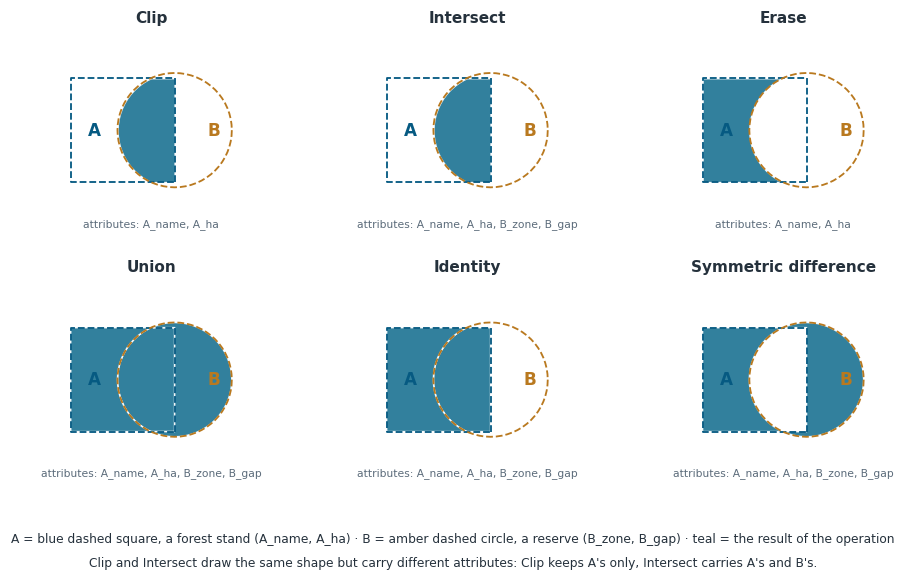

Clip — 1 row(s):


,A_name,A_ha
0,forest stand,400


Intersect — 1 row(s):


,A_name,A_ha,B_zone,B_gap
0,forest stand,400,reserve,1


Erase — 1 row(s):


...

,A_name,A_ha,B_zone,B_gap
0,forest stand,400.0,reserve,1.0
1,forest stand,400.0,NaN,NaN
2,NaN,NaN,reserve,1.0


Identity — 2 row(s):


,A_name,A_ha,B_zone,B_gap
0,forest stand,400.0,reserve,1.0
1,forest stand,400.0,NaN,NaN


Symmetric difference — 2 row(s):


,A_name,A_ha,B_zone,B_gap
0,forest stand,400.0,NaN,NaN
1,NaN,NaN,reserve,1.0


In [5]:
from shapely.geometry import box, Point
A = gpd.GeoDataFrame({"A_name": ["forest stand"], "A_ha": [400]}, geometry=[box(0, 0, 2, 2)], crs=3857)
B = gpd.GeoDataFrame({"B_zone": ["reserve"], "B_gap": [1]}, geometry=[Point(2, 1).buffer(1.1)], crs=3857)
OPS = {"Clip": gpd.clip(A, B), "Intersect": gpd.overlay(A, B, how="intersection"),
       "Erase": gpd.overlay(A, B, how="difference"), "Union": gpd.overlay(A, B, how="union"),
       "Identity": gpd.overlay(A, B, how="identity"), "Symmetric difference": gpd.overlay(A, B, how="symmetric_difference")}
print("Input A (blue square):"); display(A.drop(columns="geometry"))
print("Input B (amber circle):"); display(B.drop(columns="geometry"))
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.4)); axes = axes.ravel()
for ax, (name, g) in zip(axes, OPS.items()):
    A.boundary.plot(ax=ax, color=PAL["blue"], lw=1.2, ls="--"); B.boundary.plot(ax=ax, color=PAL["amber"], lw=1.2, ls="--")
    g.plot(ax=ax, color=PAL["teal"], edgecolor="white", lw=1.0, alpha=0.9)
    attrs = ", ".join(c for c in g.columns if c != "geometry")
    ax.set_title(name); ax.text(1.55, -0.85, f"attributes: {attrs}", ha="center", fontsize=7, color=PAL["muted"])
    ax.text(0.45, 1.0, "A", color=PAL["blue"], fontsize=11, fontweight="bold", ha="center", va="center")
    ax.text(2.75, 1.0, "B", color=PAL["amber"], fontsize=11, fontweight="bold", ha="center", va="center")
    ax.set_xlim(-0.3, 3.4); ax.set_ylim(-1.1, 2.9); ax.set_aspect("equal"); ax.set_axis_off()
fig.text(0.5, 0.02, "A = blue dashed square, a forest stand (A_name, A_ha) · B = amber dashed circle, a reserve (B_zone, B_gap) · "
         "teal = the result of the operation", ha="center", fontsize=8, color=PAL["ink"])
fig.text(0.5, -0.02, "Clip and Intersect draw the same shape but carry different attributes: Clip keeps A's only, Intersect carries A's and B's.",
         ha="center", fontsize=8, color=PAL["ink"])
save(fig, "overlay_operations.png", 13, pdf=True)
for k, g in OPS.items():                                       # every result's attribute table
    print(f"{k} — {len(g)} row(s):")
    display(g.drop(columns="geometry"))

**Reading the figure**
- **Data:** the two toy layers in the table above — A, a square forest stand (`A_name`, `A_ha`); B, a circular reserve (`B_zone`, `B_gap`) overlapping A's right half. Not real places.
- **What we did:** applied each operation to A and B with GeoPandas (`gpd.clip`, `gpd.overlay(how=...)`) and drew the result in teal; the printout above lists every result's rows and values.
- **What it shows:** **Clip and Intersect produce the same half-disc** (where A and B overlap), but Clip's table has only A's columns while Intersect's has A's *and* B's — only Intersect can tell you which reserve, and which GAP status, a piece of forest falls in. **Erase** keeps the part of A outside B. **Union** keeps everything, cut into pieces at every edge (B's columns are empty where only A exists, and vice versa). **Identity** keeps all of A, split where B covers it. **Symmetric difference** keeps everything except the overlap.

### 2.3 The same operations on the real layers
Input A = the six counties; overlay B = PAD-US units with GAP status 1–2. Watch the row count and the attribute list.

In [6]:
Acty = focus[["NAME", "STUSPS", "geometry"]]
Bpa = pad[pad.GAP <= 2][["Unit_Nm", "GAP", "Mang_Name", "geometry"]]
real = {"clip": gpd.clip(Acty, Bpa), "intersect": gpd.overlay(Acty, Bpa, how="intersection", keep_geom_type=True),
        "erase": gpd.overlay(Acty, Bpa, how="difference", keep_geom_type=True),
        "union": gpd.overlay(Acty, Bpa, how="union", keep_geom_type=True),
        "identity": gpd.overlay(Acty, Bpa, how="identity", keep_geom_type=True),
        "symmetric difference": gpd.overlay(Acty, Bpa, how="symmetric_difference", keep_geom_type=True)}
display(pd.DataFrame([{"operation": k, "rows out": len(g), "km²": round(g.area.sum() / 1e6),
                       "attributes": ", ".join(c for c in g.columns if c != "geometry")} for k, g in real.items()]).set_index("operation"))
print(f"inputs: {len(Acty)} counties, {len(Bpa)} protected units (GAP 1-2)")

,rows out,km²,attributes
operation,,,
clip,6,2085,"NAME, STUSPS"
intersect,382,2474,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"
erase,6,17642,"NAME, STUSPS"
union,409,20116,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"
identity,388,20116,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"
symmetric difference,27,17642,"NAME, STUSPS, Unit_Nm, GAP, Mang_Name"


inputs: 6 counties, 360 protected units (GAP 1-2)


**Reading the table**
- **Data:** A = the 6 focus counties (columns `NAME`, `STUSPS`); B = the 360 PAD-US units with GAP status 1–2 (columns `Unit_Nm`, `GAP`, `Mang_Name`).
- **What we did:** ran the same six operations on the real layers and recorded the number of output rows, their total area and their columns.
- **What it shows:** **Clip** returns 6 rows — one clipped piece per county — with county columns only (2,085 km²). **Intersect** returns 382 rows, one per county × protected-unit piece, and each piece now knows its unit, GAP status and manager. Intersect's area (2,474 km²) is *larger* than Clip's because PAD-US units overlap and every overlapping unit contributes its own piece; the same overlap pushes Union's area (20,116 km²) above the focus area (19,726 km²). §3.3 removes this with Dissolve. **Erase** gives the 17,642 km² of county land outside strict protection.

### 2.4 Forest × protected areas: the conservation gap (slide 14)
**Intersect** gives the protected forest, **erase** gives the gap. Both are reported for two definitions of "protected" — strict (GAP 1–2) and including multiple-use land (GAP 1–3) — because the answer depends on that choice (§6).

forest 9,860 km² | strictly protected (GAP 1-2) 1,377 km² = 14.0% | gap 8,483 km² | incl. multiple use (GAP 1-3) 7,232 km² = 73.3%


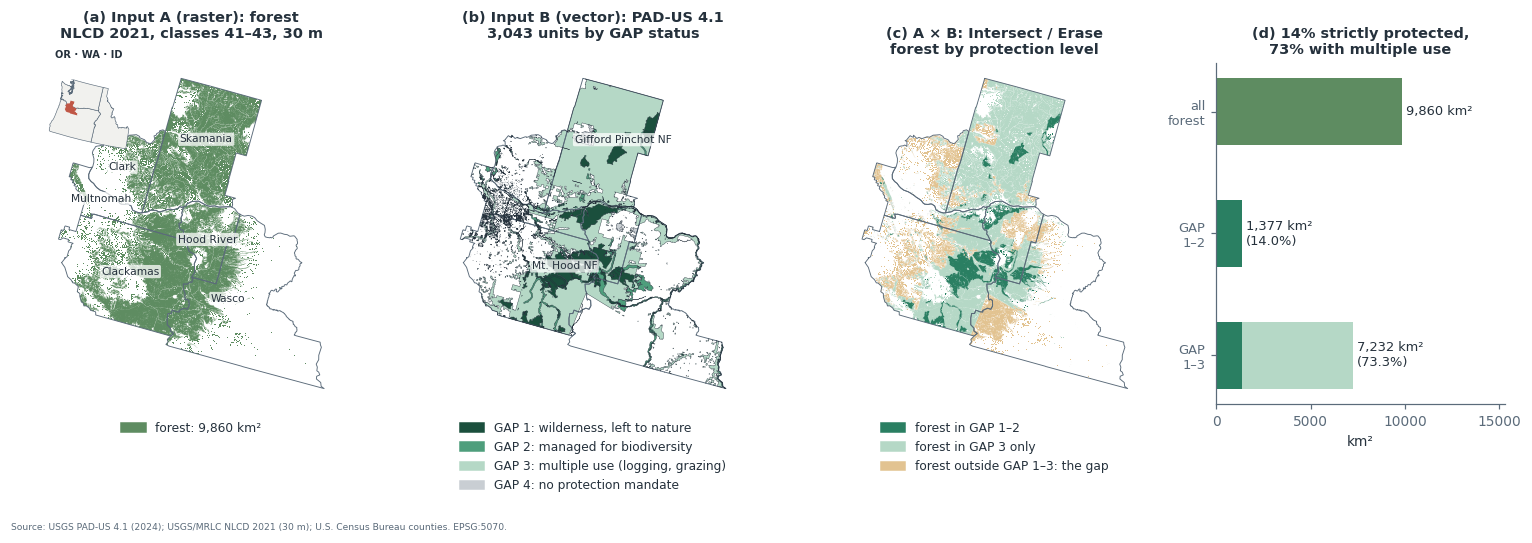

,forest km²,strictly protected km²,% protected
NAME,,,
Skamania,3516.0,209.0,5.9
Clackamas,2944.0,666.0,22.6
Wasco,1308.0,145.0,11.1
Hood River,942.0,293.0,31.1
Clark,667.0,4.0,0.6
Multnomah,483.0,60.0,12.4


CANNOT ESTABLISH: whether protected forest is in better condition than the gap. GAP status records management intent, not enforcement or outcomes; NLCD 2021 is one 30 m snapshot; PAD-US geometry was generalised to ~30 m.


In [7]:
inside12 = gpd.overlay(forest, gap12, how="intersection", keep_geom_type=True)      # forest INSIDE strict protection
gap_forest = gpd.overlay(forest, gap12, how="difference", keep_geom_type=True)    # forest OUTSIDE it: the gap
inside123 = gpd.overlay(forest, gap123, how="intersection", keep_geom_type=True)
inside3 = gpd.overlay(inside123, gap12, how="difference", keep_geom_type=True)    # forest in GAP 3 only (multiple use)
outside123 = gpd.overlay(forest, gap123, how="difference", keep_geom_type=True)   # forest outside any GAP 1-3 unit
F_km2, P12, P123 = forest.area.sum() / 1e6, inside12.area.sum() / 1e6, inside123.area.sum() / 1e6
pct12, pct123 = 100 * P12 / F_km2, 100 * P123 / F_km2
print(f"forest {F_km2:,.0f} km² | strictly protected (GAP 1-2) {P12:,.0f} km² = {pct12:.1f}% | "
      f"gap {gap_forest.area.sum() / 1e6:,.0f} km² | incl. multiple use (GAP 1-3) {P123:,.0f} km² = {pct123:.1f}%")

GAP_COL = {1: "#1B4F3D", 2: "#4E9E7C", 3: "#B5D8C6", 4: "#C9CED3"}
C_IN12, C_IN3, C_OUT = PAL["green"], "#B5D8C6", "#E2C391"
gap_by = pad.dissolve("GAP").reset_index()                        # one footprint per GAP status
fig, ax = plt.subplots(1, 4, figsize=(14, 4.7), gridspec_kw={"width_ratios": [1, 1, 1, 0.8], "wspace": 0.12})
fig.subplots_adjust(bottom=0.22, left=0.01, right=0.98)
for a in ax[:3]:
    focus.boundary.plot(ax=a, color=PAL["muted"], lw=0.6); a.set_axis_off()

# (a) input A: the forest raster, vectorised
forest.plot(ax=ax[0], color="#5E8C61", lw=0)
for _, c in focus.iterrows():
    pt = c.geometry.representative_point()
    ax[0].annotate(c.NAME, (pt.x, pt.y), ha="center", fontsize=7, color=PAL["ink"],
                   bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax[0].set_title("(a) Input A (raster): forest\nNLCD 2021, classes 41–43, 30 m", fontsize=9.5)
loc = ax[0].inset_axes([0.0, 0.70, 0.30, 0.30])                  # where the focus area sits in OR / WA
states = gpd.read_file(VEC / "us_states.shp").to_crs(ALBERS)
states[states.state_abbr.isin(["OR", "WA", "ID"])].plot(ax=loc, color="#F1F1EE", edgecolor=PAL["muted"], lw=0.4)
focus.dissolve().plot(ax=loc, color=PAL["terra"], lw=0)
loc.set_axis_off(); loc.set_title("OR · WA · ID", fontsize=6.5, pad=1)
ax[0].legend([Patch(color="#5E8C61")], [f"forest: {F_km2:,.0f} km²"], loc="upper center", bbox_to_anchor=(0.5, -0.02),
             fontsize=8, frameon=False)

# (b) input B: PAD-US polygons coloured by GAP status, strongest drawn on top
for g in (4, 3, 2, 1):
    sub = gap_by[gap_by.GAP == g]
    sub.plot(ax=ax[1], color=GAP_COL[g], lw=0)
    sub.boundary.plot(ax=ax[1], color=PAL["ink"], lw=0.25)
for unit, txt in [("Mt. Hood National Forest", "Mt. Hood NF"), ("Gifford Pinchot National Forest", "Gifford Pinchot NF"),
]:
    u = pad[pad.Unit_Nm == unit]
    if len(u):
        pt = u.union_all().representative_point()
        ax[1].annotate(txt, (pt.x, pt.y), ha="center", fontsize=7, color=PAL["ink"],
                       bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax[1].set_title(f"(b) Input B (vector): PAD-US 4.1\n{len(pad):,} units by GAP status", fontsize=9.5)
ax[1].legend([Patch(color=GAP_COL[g]) for g in (1, 2, 3, 4)],
             ["GAP 1: wilderness, left to nature", "GAP 2: managed for biodiversity", "GAP 3: multiple use (logging, grazing)",
              "GAP 4: no protection mandate"], loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8, frameon=False)

# (c) the overlay: forest split by the strongest protection it falls under
outside123.plot(ax=ax[2], color=C_OUT, lw=0)
inside3.plot(ax=ax[2], color=C_IN3, lw=0)
inside12.plot(ax=ax[2], color=C_IN12, lw=0)
ax[2].set_title("(c) A × B: Intersect / Erase\nforest by protection level", fontsize=9.5)
ax[2].legend([Patch(color=C_IN12), Patch(color=C_IN3), Patch(color=C_OUT)],
             ["forest in GAP 1–2", "forest in GAP 3 only", "forest outside GAP 1–3: the gap"],
             loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8, frameon=False)

# (d) areas
a2 = ax[3]
labels = ["all\nforest", "GAP\n1–2", "GAP\n1–3"]
a2.barh(labels, [F_km2, P12, P12], color=["#5E8C61", C_IN12, C_IN12], height=0.55)
a2.barh(labels[2], P123 - P12, left=P12, color=C_IN3, height=0.55)                  # GAP 3 share, same colour as (c)
for k, v in enumerate([F_km2, P12, P123]):
    a2.text(v + F_km2 * 0.02, k, f"{v:,.0f} km²" + ("" if k == 0 else f"\n({100 * v / F_km2:.1f}%)"), va="center", fontsize=8.5)
a2.invert_yaxis(); a2.set_xlim(0, F_km2 * 1.55); a2.set_xlabel("km²"); a2.tick_params(axis="y", labelsize=8.5)
for side in ("top", "right"):
    a2.spines[side].set_visible(False)
a2.set_title(f"(d) {pct12:.0f}% strictly protected,\n{pct123:.0f}% with multiple use", fontsize=9.5)
source(fig, "USGS PAD-US 4.1 (2024); USGS/MRLC NLCD 2021 (30 m); U.S. Census Bureau counties. EPSG:5070.")
save(fig, "overlay_policy_forest_protected.png", 14)

per = (gpd.overlay(inside12, focus[["NAME", "geometry"]], how="intersection", keep_geom_type=True)
       .assign(km2=lambda d: d.area / 1e6).groupby("NAME").km2.sum())
allf = (gpd.overlay(forest, focus[["NAME", "geometry"]], how="intersection", keep_geom_type=True)
        .assign(km2=lambda d: d.area / 1e6).groupby("NAME").km2.sum())
t = pd.DataFrame({"forest km²": allf.round(0), "strictly protected km²": per.reindex(allf.index).fillna(0).round(0)})
t["% protected"] = (100 * t.iloc[:, 1] / t.iloc[:, 0]).round(1)
display(t.sort_values("forest km²", ascending=False))
cannot("whether protected forest is in better condition than the gap. GAP status records management intent, not "
       "enforcement or outcomes; NLCD 2021 is one 30 m snapshot; PAD-US geometry was generalised to ~30 m.")

**Reading the figure**
- **Data:** *(a) Input A, raster:* NLCD 2021 land cover, 30 m; forest = classes 41–43 (deciduous, evergreen, mixed), 9,860 km², converted to polygons. The inset shows where the six counties lie. *(b) Input B, vector:* the 3,043 PAD-US 4.1 units in the six counties, each with a **GAP status** (USGS Gap Analysis Project) — **1** wilderness left to natural processes (Mount Hood, Mark O. Hatfield, Salmon-Huckleberry wildernesses); **2** managed for biodiversity (White River Wildlife Area, wild-and-scenic river corridors); **3** protected from conversion but open to logging, grazing and mining (Mt. Hood and Gifford Pinchot national forests, the Columbia Gorge Scenic Area); **4** no known protection mandate.
- **What we did:** dissolved the units into a strict layer (GAP 1–2) and a broad one (GAP 1–3); **Intersect**ed the forest with each and **Erase**d it from each. *(c)* colours every piece of forest by the strongest protection it falls under; *(d)* gives the areas, with the bar colours matching *(c)*.
- **What it shows:** compare (b) and (c): the dark-green wilderness patches in (b) are the only places where the forest in (c) is dark green — **1,377 km², 14.0 % of the forest**. The light-green national forests that cover most of (b) add 5,855 km², taking the total to **7,232 km², 73.3 %**. The tan forest in (c) lies outside every GAP 1–3 unit — mainly in Clackamas (831 km²), Wasco (687 km²) and Clark (469 km²) — on land PAD-US does not record as GAP 1–3 (private, tribal, state or local land, or GAP 4). The "conservation gap" is 86 % or 27 % of the forest depending on one definition — a policy choice, not a GIS output (§6.1).

---
## 3 · Buffer, Distance and Proximity  (slides 15–21) · **LO 1**
A **buffer** turns distance into yes/no; a **distance surface** keeps it continuous. *The buffer distance is an assumption* (slide 16): state it and show how far the answer moves when it changes. Distances are measured in metre-based CRSs (EPSG:5070 here, UTM 46N in Cox's Bazar).

### 3.1 Distance to water and development (slide 18)
Every 30 m cell gets its exact Euclidean distance to the nearest open-water cell (NLCD class 11).

,land km²,% developed
distance to water (m),,
0–100,522,7.7
100–250,448,17.7
250–500,880,15.4
0.5–1k,1926,13.4
1–2k,3627,11.1
2–5k,7277,8.0
>5k,5047,3.2


median distance to water: developed cells 1,758 m vs all land 2,806 m


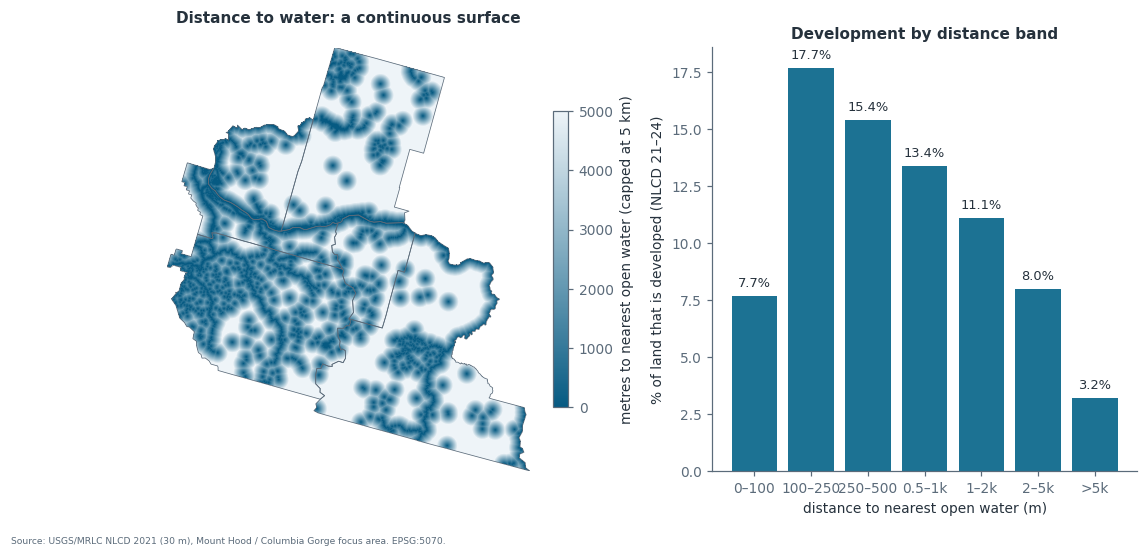

CANNOT ESTABLISH: that water causes development. Portland grew on the Columbia for transport; terrain, roads and zoning co-vary with distance to water. Straight-line distance also ignores that a river is often a barrier.


In [8]:
dist = ndimage.distance_transform_edt(lc != 11, sampling=30.0)
dist = np.where(land, dist, np.nan)
developed = np.isin(lc, [21, 22, 23, 24]) & land
edges = np.array([0, 100, 250, 500, 1000, 2000, 5000, np.inf])
labels = ["0–100", "100–250", "250–500", "0.5–1k", "1–2k", "2–5k", ">5k"]
band = np.digitize(np.nan_to_num(dist, nan=-1), edges) - 1
prox = pd.DataFrame([{"distance to water (m)": lab, "land km²": round((land & (band == b)).sum() * CELL_KM2),
                      "% developed": 100 * (developed & (band == b)).sum() / max((land & (band == b)).sum(), 1)}
                     for b, lab in enumerate(labels)]).set_index("distance to water (m)")
display(prox.round(1))
print(f"median distance to water: developed cells {np.nanmedian(dist[developed]):,.0f} m vs all land {np.nanmedian(dist[land]):,.0f} m")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={"width_ratios": [1.1, 1]})
im = a1.imshow(np.clip(dist, 0, 5000), extent=lc_ext, cmap=SEQ_BLUE.reversed(), interpolation="nearest")
focus.boundary.plot(ax=a1, color=PAL["muted"], lw=0.5)
fig.colorbar(im, ax=a1, shrink=0.7, label="metres to nearest open water (capped at 5 km)")
a1.set_title("Distance to water: a continuous surface"); a1.set_axis_off()
a2.bar(prox.index, prox["% developed"], color=PAL["teal"])
for k, v in enumerate(prox["% developed"]):
    a2.text(k, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8.5)
a2.set_ylabel("% of land that is developed (NLCD 21–24)"); a2.set_xlabel("distance to nearest open water (m)")
a2.set_title("Development by distance band")
source(fig, "USGS/MRLC NLCD 2021 (30 m), Mount Hood / Columbia Gorge focus area. EPSG:5070.")
save(fig, "distance_to_water_development.png", 18)
cannot("that water causes development. Portland grew on the Columbia for transport; terrain, roads and zoning "
       "co-vary with distance to water. Straight-line distance also ignores that a river is often a barrier.")

**Reading the figure**
- **Data:** NLCD 2021 at 30 m for the focus area; *water* = class 11, *developed* = classes 21–24.
- **What we did:** computed for every land cell its straight-line distance to the nearest water cell (left map, capped at 5 km), grouped the cells into 7 distance bands, and computed the share developed in each band (right, and the table above).
- **What it shows:** development **peaks 100–250 m from water (17.7 %) and falls steadily to 3.2 % beyond 5 km**. The 0–100 m band is lower (7.7 %) because river banks, floodplains and wetlands are rarely built on. Developed land is closer to water than land in general (median 1.76 km vs 2.81 km). This is an association, not a cause — see the CANNOT ESTABLISH line.

### 3.2 Humanitarian track: refugee camps and conflict events (slides 19–20)
*"Which refugee camps fall within X km of conflict zones?"* — the syllabus task, on real data: the 33 camp outlines of the **Rohingya camps in Cox's Bazar** (ISCG, CC0) and **UCDP GED 2023** events within 300 km. Camps are kept as **whole-camp polygons**: no blocks, no shelters, nothing that locates households.

In [9]:
camps = gpd.read_file(VEC8 / "coxsbazar_camps_2023.shp")                     # EPSG:32646 (UTM 46N, metres)
ev = pd.read_csv(TAB8 / "ucdp_ged_2023_near_camps.csv")
evp = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev.longitude, ev.latitude), crs=4326).to_crs(camps.crs)
print(f"{len(camps)} camps ({camps.AreaSqKM.sum():.1f} km²) | {len(evp)} UCDP 2023 events within 300 km "
      f"({evp.country.value_counts().to_dict()})")

D = np.array([evp.distance(g).values for g in camps.geometry]) / 1000          # km: camps x events
camps["nearest_km"] = D.min(axis=1)
camps["third_km"] = np.sort(D, axis=1)[:, 2]                                   # 3rd-nearest: less sensitive to one event
RADII = [1, 2, 5, 10, 25, 50, 100]
share1 = [100 * (D <= r).any(axis=1).mean() for r in RADII]
share3 = [100 * ((D <= r).sum(axis=1) >= 3).mean() for r in RADII]
display(pd.DataFrame({"radius km": RADII, "% camps with ≥1 event within": np.round(share1, 0),
                      "% camps with ≥3 events within": np.round(share3, 0)}).set_index("radius km").T)
print(f"median distance camp -> nearest event {camps.nearest_km.median():.1f} km, -> 3rd nearest {camps.third_km.median():.1f} km")
precise = (evp.where_prec <= 2).values                                   # UCDP: 1 = exact, 2 = within ~25 km
share1_precise = [100 * (D[:, precise] <= r).any(axis=1).mean() for r in RADII]
print(f"location precision of the {len(evp)} events: {evp.where_prec.value_counts().sort_index().to_dict()}")
print("precise events only (where_prec <= 2):", [f"{v:.0f}%" for v in share1_precise],
      "-> same as all events" if np.allclose(share1, share1_precise) else "-> differs: report both")

33 camps (23.6 km²) | 410 UCDP 2023 events within 300 km ({'Myanmar (Burma)': 399, 'Bangladesh': 10, 'India': 1})


radius km,1,2,5,10,25,50,100
% camps with ≥1 event within,64.0,79.0,97.0,100.0,100.0,100.0,100.0
% camps with ≥3 events within,27.0,45.0,76.0,85.0,100.0,100.0,100.0


median distance camp -> nearest event 0.8 km, -> 3rd nearest 2.4 km
location precision of the 410 events: {1: 114, 2: 57, 3: 3, 4: 3, 5: 233}
precise events only (where_prec <= 2): ['64%', '79%', '97%', '100%', '100%', '100%', '100%'] -> same as all events


**Reading the table**
- **Data:** 33 camp outlines (26 in Ukhia, 7 in Teknaf) and 410 UCDP 2023 events within 300 km (399 in Myanmar, 10 in Bangladesh, 1 in India).
- **What we did:** measured, in metres (UTM 46N), the distance from every camp polygon to every event; then, for each radius, counted the share of camps with at least 1 — or at least 3 — events within that radius.
- **What it shows:** the median camp is **0.8 km from its nearest event** and 2.4 km from its third-nearest: several 2023 events were recorded in or right next to the camps. Restricting to precisely located events (UCDP `where_prec` ≤ 2) gives exactly the same shares.

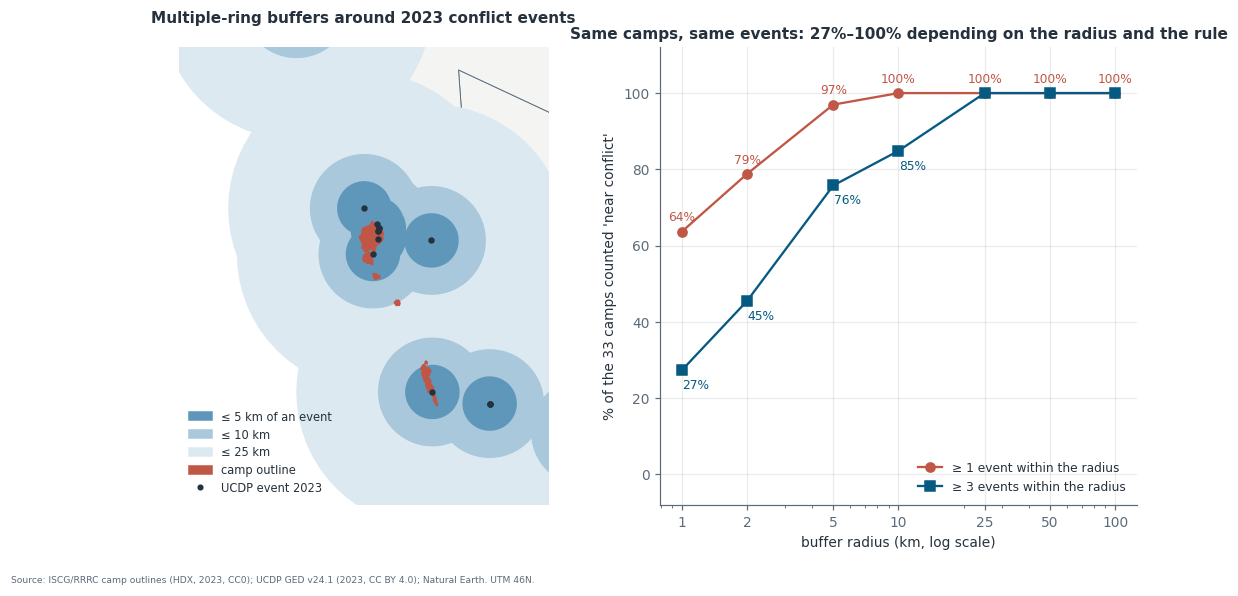

In [10]:
world = gpd.read_file(VEC / "world_countries_ne110m.shp")
cu = camps.union_all().centroid
view = (cu.x - 38_000, cu.y - 42_000, cu.x + 30_000, cu.y + 42_000)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
world[world.NAME.isin(["Bangladesh", "Myanmar", "India"])].to_crs(camps.crs).plot(ax=a1, color="#F4F4F2", edgecolor=PAL["muted"], lw=0.6)
prev = None
for r, c in zip([25, 10, 5], ["#DCE9F1", "#A9C8DB", "#5E97B9"]):
    zone = evp.buffer(r * 1000).union_all()
    gpd.GeoSeries([zone], crs=camps.crs).plot(ax=a1, color=c, lw=0)
camps.plot(ax=a1, color=PAL["terra"], edgecolor=PAL["terra"], lw=1.2)
evp.plot(ax=a1, color=PAL["ink"], markersize=10)
a1.set_xlim(view[0], view[2]); a1.set_ylim(view[1], view[3]); a1.set_axis_off()
a1.legend([Patch(color="#5E97B9"), Patch(color="#A9C8DB"), Patch(color="#DCE9F1"), Patch(color=PAL["terra"]),
           Line2D([], [], ls="", marker="o", color=PAL["ink"], ms=3)],
          ["≤ 5 km of an event", "≤ 10 km", "≤ 25 km", "camp outline", "UCDP event 2023"], loc="lower left", fontsize=7.5)
a1.set_title("Multiple-ring buffers around 2023 conflict events")
a2.plot(RADII, share1, "o-", color=PAL["terra"], label="≥ 1 event within the radius")
a2.plot(RADII, share3, "s-", color=PAL["blue"], label="≥ 3 events within the radius")
for r, v1, v3 in zip(RADII, share1, share3):
    a2.annotate(f"{v1:.0f}%", (r, v1), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=PAL["terra"])
    if abs(v1 - v3) > 4:                                       # one label when the two lines coincide
        a2.annotate(f"{v3:.0f}%", (r, v3), xytext=(9, -12), textcoords="offset points", ha="center", fontsize=8, color=PAL["blue"])
a2.set_xscale("log"); a2.set_xticks(RADII, [str(r) for r in RADII]); a2.set_ylim(-8, 112)
a2.set_xlabel("buffer radius (km, log scale)"); a2.set_ylabel("% of the 33 camps counted 'near conflict'")
a2.legend(loc="lower right", fontsize=8); a2.grid(alpha=0.25)
a2.set_title(f"Same camps, same events: {min(share1 + share3):.0f}%–{max(share1 + share3):.0f}% depending on the radius and the rule")
source(fig, "ISCG/RRRC camp outlines (HDX, 2023, CC0); UCDP GED v24.1 (2023, CC BY 4.0); Natural Earth. UTM 46N.")
save(fig, "buffer_sensitivity.png", 20)

**Reading the figure**
- **Data:** as above; the map zooms on the camps and the Bangladesh–Myanmar border.
- **What we did:** *Left* — buffers of 5, 10 and 25 km around every event (darker = closer), camps in red. *Right* — the share of the 33 camps counted "near conflict" at seven radii — 1, 2, 5, 10, 25, 50 and 100 km — under two rules (≥ 1 event, ≥ 3 events within the radius). The tick labels are ordinary kilometres; only the spacing is logarithmic (each step multiplies the radius rather than adding to it), so the short radii, where the share changes fastest, are not squeezed into the left edge.
- **What it shows:** two choices move the answer, and they are separate:
  - **The radius.** Under the "≥ 1 event" rule (red line), 64 % of camps are "near conflict" at 1 km, 79 % at 2 km, 97 % at 5 km, and all of them from 10 km on.
  - **The rule.** Under the stricter "≥ 3 events" rule (blue line) the curve is lower at every radius and reaches 100 % only at 25 km. Read the two lines at the **same** radius to see the effect of the rule alone: at 1 km 64 % vs 27 %; at 5 km 97 % vs 76 %; at 10 km 100 % vs 85 %. From 25 km on both rules give 100 %, so they no longer separate the camps at all.
  - So "how many camps are at risk?" has no single answer: it ranges from 27 % to 100 % depending on the radius *and* the rule. The memo must state and justify both.

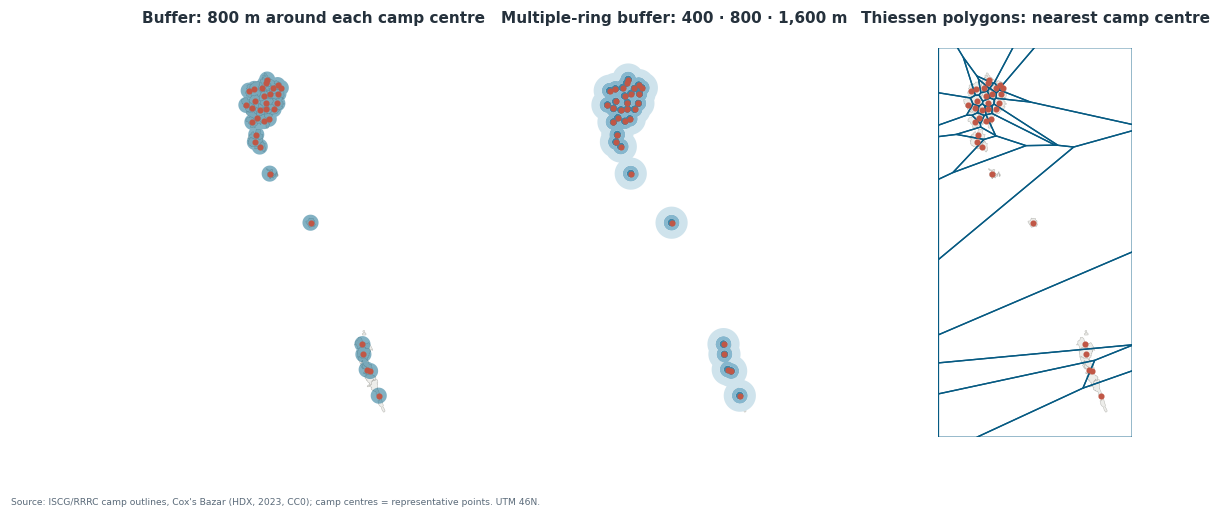

CANNOT ESTABLISH: that a camp near an event is at higher risk. UCDP geocodes events at different precisions (where_prec), Euclidean buffers ignore the border, the Naf river and roads, and 2023 is one year. Thiessen polygons assume people use the nearest point, which camp boundaries contradict.


In [11]:
from shapely.geometry import MultiPoint
from shapely.ops import voronoi_diagram
cp = camps.representative_point()
frame = camps.union_all().buffer(2500).envelope
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax in axes:
    camps.plot(ax=ax, color="#EDEDEA", edgecolor="#B5B5B0", lw=0.3)
gpd.GeoSeries([cp.buffer(800).union_all()], crs=camps.crs).plot(ax=axes[0], color=PAL["teal"], alpha=0.55, lw=0)
axes[0].set_title("Buffer: 800 m around each camp centre")
prev = None
for d, c in zip([400, 800, 1600], ["#3D86A8", "#86B7CE", "#CFE3EC"]):
    cur = cp.buffer(d).union_all()
    gpd.GeoSeries([cur if prev is None else cur.difference(prev)], crs=camps.crs).plot(ax=axes[1], color=c, lw=0)
    prev = cur
axes[1].set_title("Multiple-ring buffer: 400 · 800 · 1,600 m")
vor = gpd.GeoSeries([g.intersection(frame) for g in voronoi_diagram(MultiPoint(list(cp)), envelope=frame).geoms], crs=camps.crs)
vor.boundary.plot(ax=axes[2], color=PAL["blue"], lw=0.9)
axes[2].set_title("Thiessen polygons: nearest camp centre")
x0, y0, x1, y1 = frame.bounds
for ax in axes:
    cp.plot(ax=ax, color=PAL["terra"], markersize=9, zorder=5)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal"); ax.set_axis_off()
source(fig, "ISCG/RRRC camp outlines, Cox's Bazar (HDX, 2023, CC0); camp centres = representative points. UTM 46N.")
save(fig, "proximity_toolbox.png", 19, pdf=True)
cannot("that a camp near an event is at higher risk. UCDP geocodes events at different precisions (where_prec), "
       "Euclidean buffers ignore the border, the Naf river and roads, and 2023 is one year. Thiessen polygons "
       "assume people use the nearest point, which camp boundaries contradict.")

**Reading the figure**
- **Data:** one point per camp — a representative point inside each of the 33 camp outlines (outlines in grey).
- **What we did:** three proximity tools on the same points: a single 800 m buffer; rings at 400, 800 and 1,600 m; and Thiessen (Voronoi) polygons, which assign every location to its nearest camp centre.
- **What it shows:** in the dense northern cluster (Ukhia) the buffers merge into one zone and the Thiessen cells are small and cut across the camp outlines themselves; around the scattered southern camps (Teknaf) the cells become very large. The "nearest centre" rule ignores the real boundaries people live within.

### 3.3 Data preprocessing: dissolve and integrate (slide 21)
**Dissolve** merges features that share a value. PAD-US records overlap (a wilderness inside a national forest inside a scenic area), so summing the raw records double-counts land. **Integrate** makes vertices within a tolerance coincide, removing slivers between neighbours — here between PAD-US *fee* parcels whose shared edges were generalised independently.

dissolve: 3,043 features summing to 15,665 km² -> by GAP status 4 features, 12,352 km² (overlaps between GAP classes remain) -> dissolve all: footprint 9,977 km²; summing raw records overstates protected land by 57%
integrate (30 m): fee parcels 2,434 -> 2,230; small overlaps 540 -> 206; small gaps 483 -> 250


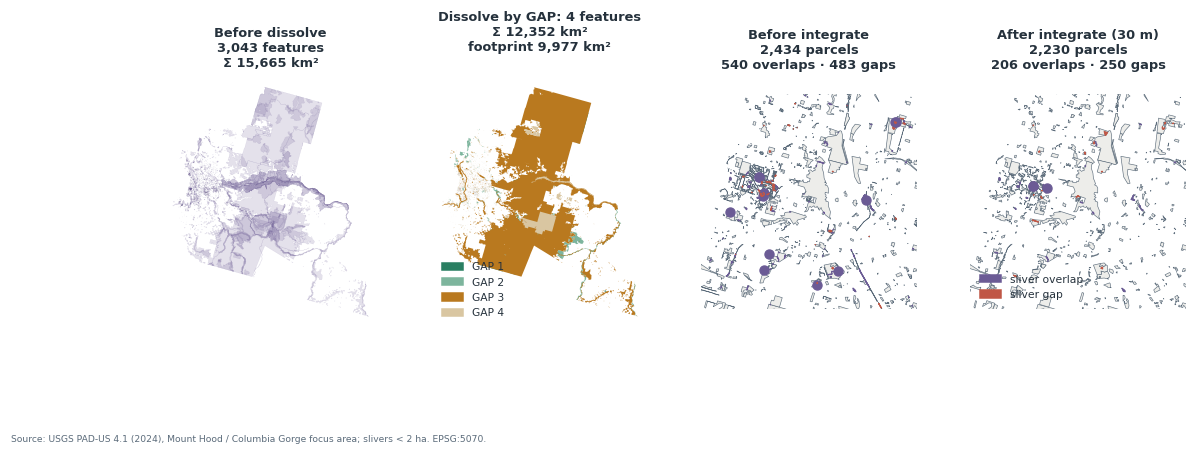

Integrate also deleted 204 parcels smaller than the 30 m tolerance — the tolerance is a choice too.


In [12]:
raw_sum = pad.area.sum() / 1e6
diss = pad.dissolve(by="GAP", as_index=False)
diss_km2 = diss.area.sum() / 1e6
footprint_km2 = pad.union_all().area / 1e6                     # dissolve everything: the true footprint
fee = pad[pad.Category == "Fee"].reset_index(drop=True)


def slivers(gdf, small=20_000):
    pr = gpd.sjoin(gdf[["geometry"]], gdf[["geometry"]], predicate="intersects")
    pr = pr[pr.index < pr.index_right]
    inter = [gdf.geometry[a].intersection(gdf.geometry[b]) for a, b in zip(pr.index, pr.index_right)]
    over = [g for g in inter if 1 < g.area < small]
    u = gdf.union_all()
    holes = [shapely.Polygon(r) for p in getattr(u, "geoms", [u]) for r in p.interiors]
    gaps = [h for h in holes if h.area < small]
    return over, gaps


TOL = 30                                                       # metres = the generalisation tolerance of the data
fee_int = fee.set_geometry(shapely.set_precision(fee.geometry.values, grid_size=TOL))
fee_int = fee_int[~fee_int.is_empty].reset_index(drop=True)
ov0, gp0 = slivers(fee); ov1, gp1 = slivers(fee_int)
print(f"dissolve: {len(pad):,} features summing to {raw_sum:,.0f} km² -> by GAP status {len(diss)} features, {diss_km2:,.0f} km² "
      f"(overlaps between GAP classes remain) -> dissolve all: footprint {footprint_km2:,.0f} km²; "
      f"summing raw records overstates protected land by {100 * (raw_sum / footprint_km2 - 1):.0f}%")
print(f"integrate ({TOL} m): fee parcels {len(fee):,} -> {len(fee_int):,}; small overlaps {len(ov0)} -> {len(ov1)}; "
      f"small gaps {len(gp0)} -> {len(gp1)}")

centres = np.array([[g.centroid.x, g.centroid.y] for g in ov0 + gp0])
dens = cKDTree(centres).query_ball_point(centres, r=6000, return_length=True)
cx, cy = centres[dens.argmax()]
win = (cx - 6000, cy - 6000, cx + 6000, cy + 6000)
GAPC = {1: PAL["green"], 2: "#7DB59D", 3: PAL["amber"], 4: "#D9C6A1"}
fig, axes = plt.subplots(1, 4, figsize=(12, 4.2), gridspec_kw={"wspace": 0.25})
pad.plot(ax=axes[0], color=PAL["purple"], alpha=0.18, edgecolor=PAL["purple"], lw=0.2)
axes[0].set_title(f"Before dissolve\n{len(pad):,} features\nΣ {raw_sum:,.0f} km²", fontsize=8.5)
diss.plot(ax=axes[1], color=[GAPC[g] for g in diss.GAP], lw=0)
axes[1].legend([Patch(color=GAPC[g]) for g in diss.GAP], [f"GAP {g}" for g in diss.GAP], loc="lower left", fontsize=7)
axes[1].set_title(f"Dissolve by GAP: {len(diss)} features\nΣ {diss_km2:,.0f} km²\nfootprint {footprint_km2:,.0f} km²", fontsize=8.5)
for ax, data, ov, gp, ttl in [(axes[2], fee, ov0, gp0, "Before integrate"), (axes[3], fee_int, ov1, gp1, f"After integrate ({TOL} m)")]:
    data.cx[win[0]:win[2], win[1]:win[3]].plot(ax=ax, color="#EDEDEA", edgecolor=PAL["muted"], lw=0.4)
    for gs, col in [(ov, PAL["purple"]), (gp, PAL["terra"])]:
        if gs:
            gpd.GeoSeries(gs, crs=ALBERS).cx[win[0]:win[2], win[1]:win[3]].plot(ax=ax, color=col, lw=0.8, edgecolor=col)
    ax.set_xlim(win[0], win[2]); ax.set_ylim(win[1], win[3])
    ax.set_title(f"{ttl}\n{len(data):,} parcels\n{len(ov)} overlaps · {len(gp)} gaps", fontsize=8.5)
axes[3].legend([Patch(color=PAL["purple"]), Patch(color=PAL["terra"])], ["sliver overlap", "sliver gap"], loc="lower left", fontsize=7)
for ax in axes:
    ax.set_aspect("equal"); ax.set_axis_off()
source(fig, "USGS PAD-US 4.1 (2024), Mount Hood / Columbia Gorge focus area; slivers < 2 ha. EPSG:5070.")
save(fig, "data_preprocessing_dissolve_integrate.png", 21, pdf=True)
print(f"Integrate also deleted {len(fee) - len(fee_int)} parcels smaller than the {TOL} m tolerance — the tolerance is a choice too.")

**Reading the figure**
- **Data:** the 3,043 PAD-US records in the focus area; for Integrate, the 2,434 *fee* (ownership) parcels, shown for the 12 × 12 km window with the most slivers.
- **What we did:** *Dissolve* — merged the records by GAP status (panel 2) and, separately, merged everything into one footprint. *Integrate* — snapped all vertices to a 30 m grid so nearly-coincident edges become identical; counted small overlaps (purple) and gaps (red) under 2 ha before and after.
- **What it shows:** adding up the raw records gives 15,665 km², but the land actually covered is **9,977 km² — summing records overstates protected land by 57 %**. Dissolving by GAP status still leaves 12,352 km², because different GAP classes overlap. Integrate cuts overlaps from 540 to 206 and gaps from 483 to 250, but also **deletes 204 parcels** smaller than the tolerance: the tolerance is an analytical choice too.

---
## 4 · Patterns, Clusters and Hotspots  (slides 22–29) · **LO 2**
*Is this pattern real, or could chance produce it?* (slide 24). Compute a statistic, reshuffle the values across the same geography many times, and see where the real value falls. §4.1 and §4.3 use the contiguous-U.S. counties and the queen weights from §1; §4.4 compares three point layers: earthquakes, random points and county points.

### 4.1 Global Moran's I and LISA (slide 25)

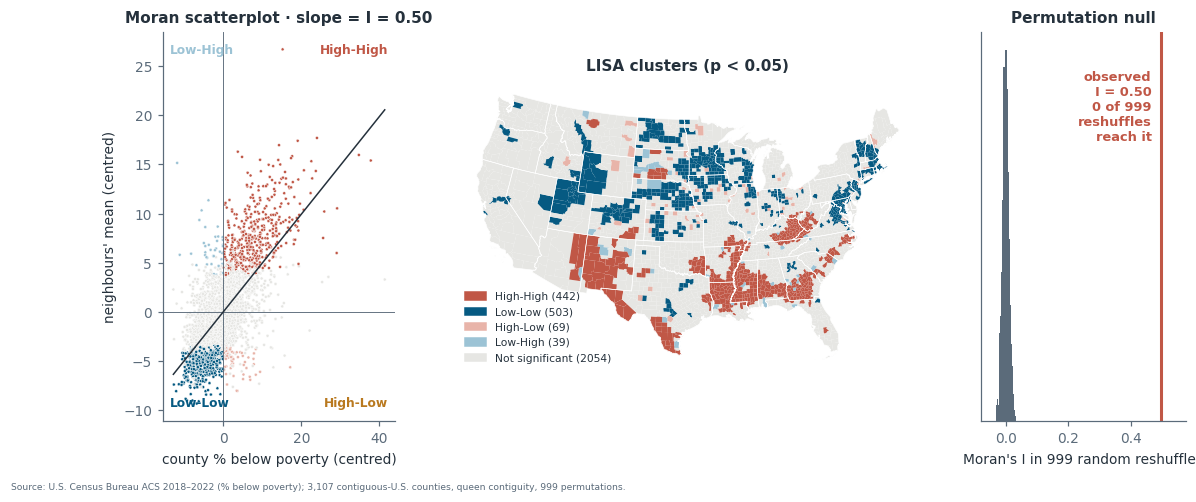

Global Moran's I = 0.496, pseudo p = 0.001, n = 3107; LISA classes: {'Not significant': 2054, 'Low-Low': 503, 'High-High': 442, 'High-Low': 69, 'Low-High': 39}
999 reshuffles: I from -0.030 to 0.034
High-High counties by state (top 8): {'GA': 66, 'MS': 61, 'KY': 55, 'LA': 39, 'TX': 35, 'AR': 32, 'AL': 28, 'NM': 18}
Low-Low counties by state (top 8): {'NE': 52, 'MN': 51, 'IA': 42, 'VA': 38, 'WI': 33, 'KS': 23, 'ND': 23, 'CO': 22}


In [13]:
z = R.poverty_pct.values - R.poverty_pct.mean()
n = len(z)
moran_I = (z @ (W @ z)) / (z @ z)                              # S0 = n under row standardisation
perm = np.column_stack([RNG.permutation(z) for _ in range(999)])
I_null = np.einsum("ij,ij->j", perm, W @ perm) / np.einsum("ij,ij->j", perm, perm)
p_moran = (np.sum(I_null >= moran_I) + 1) / 1000

m2 = (z @ z) / n
lagz = W @ z
Ii = z * lagz / m2
kk = kdeg.astype(int)
p_loc = np.empty(n)
for idx in range(n):                                           # conditional permutation
    draw = RNG.integers(0, n - 1, size=(999, kk[idx])); draw[draw >= idx] += 1
    sim = z[idx] * z[draw].mean(axis=1) / m2
    larger = (sim >= Ii[idx]).sum()
    p_loc[idx] = (min(larger, 999 - larger) + 1) / 1000
quad = np.select([(z > 0) & (lagz > 0), (z < 0) & (lagz < 0), (z > 0) & (lagz < 0), (z < 0) & (lagz > 0)],
                 ["High-High", "Low-Low", "High-Low", "Low-High"], default="")
R["lisa"] = np.where(p_loc < 0.05, quad, "Not significant")
LISA_COL = {"High-High": PAL["terra"], "Low-Low": PAL["blue"], "High-Low": "#E8B4A9", "Low-High": "#9CC3D5", "Not significant": "#E6E6E3"}
cnt = R.lisa.value_counts()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw={"width_ratios": [0.85, 1.7, 0.75]})
axes[0].scatter(z, lagz, s=4, c=[LISA_COL[v] for v in R.lisa], edgecolor="white", lw=0.3)
axes[0].axhline(0, color=PAL["muted"], lw=0.6); axes[0].axvline(0, color=PAL["muted"], lw=0.6)
xs = np.array([z.min(), z.max()]); axes[0].plot(xs, moran_I * xs, color=PAL["ink"], lw=1)
for (qx, qy, t) in [(0.97, 0.97, "High-High"), (0.03, 0.03, "Low-Low"), (0.97, 0.03, "High-Low"), (0.03, 0.97, "Low-High")]:
    axes[0].text(qx, qy, t, transform=axes[0].transAxes, ha="right" if qx > 0.5 else "left", va="top" if qy > 0.5 else "bottom",
                 fontsize=8, color=LISA_COL[t] if t != "High-Low" else PAL["amber"], fontweight="bold")
axes[0].set_xlabel("county % below poverty (centred)"); axes[0].set_ylabel("neighbours' mean (centred)")
axes[0].set_title(f"Moran scatterplot · slope = I = {moran_I:.2f}")
R.plot(ax=axes[1], color=R.lisa.map(LISA_COL), edgecolor="none")
STATE_LINES.plot(ax=axes[1], color="white", lw=0.4)
axes[1].legend([Patch(color=c) for c in LISA_COL.values()], [f"{k} ({cnt.get(k, 0)})" for k in LISA_COL],
               loc="lower left", fontsize=7)
axes[1].set_title("LISA clusters (p < 0.05)"); axes[1].set_axis_off()
axes[2].hist(I_null, bins=35, color=PAL["muted"], edgecolor="none")
axes[2].axvline(moran_I, color=PAL["terra"], lw=2)
axes[2].set_xlim(I_null.min() - 0.05, moran_I + 0.08)
axes[2].annotate(f"observed\nI = {moran_I:.2f}\n{int((I_null >= moran_I).sum())} of 999\nreshuffles\nreach it", (moran_I, axes[2].get_ylim()[1] * 0.9),
                 xytext=(-6, 0), textcoords="offset points", ha="right", va="top", color=PAL["terra"], fontsize=8.5, fontweight="bold")
axes[2].set_yticks([]); axes[2].set_xlabel("Moran's I in 999 random reshuffles"); axes[2].set_title("Permutation null")
source(fig, f"U.S. Census Bureau ACS 2018–2022 (% below poverty); {n:,} contiguous-U.S. counties, queen contiguity, 999 permutations.")
save(fig, "clusters_moran_lisa.png", 25)
print(f"Global Moran's I = {moran_I:.3f}, pseudo p = {p_moran:.3f}, n = {n}; LISA classes: {cnt.to_dict()}")
print(f"999 reshuffles: I from {I_null.min():.3f} to {I_null.max():.3f}")
for k in ["High-High", "Low-Low"]:
    print(f"{k} counties by state (top 8):", R[R.lisa == k].state_abbr.value_counts().head(8).to_dict())

**Reading the figure**
- **Data:** % below poverty for the 3,107 contiguous-U.S. counties from §1; neighbours = counties sharing a border or a corner (queen contiguity).
- **What we did:** Global Moran's I (one number for the whole map; the slope of the line in the left panel), its significance from 999 random reshuffles of the values (right), and Local Moran / LISA (one label per county, p < 0.05; middle).
- **What it shows:**
  - **I = 0.50, pseudo p = 0.001** (the smallest value 999 reshuffles can give): reshuffled maps give I between about −0.03 and +0.03, and **none reached 0.50**. Strong positive spatial autocorrelation.
  - **High-High (442 counties, poor among poor)** form the regions seen in §1: Georgia (66), Mississippi (61), Kentucky (55), Louisiana (39), Texas (35), Arkansas (32), Alabama (28), New Mexico (18). **Low-Low (503)** cover the Upper Midwest (Nebraska 52, Minnesota 51, Iowa 42, Wisconsin 33), northern Virginia and the Washington DC suburbs, and the Colorado–Utah Front Range.
  - **Outliers are small and worth a look:** 69 High-Low counties (a poor county among richer neighbours, e.g. Riley KS, home of a large university, and Philadelphia PA, a city ringed by suburbs) and 39 Low-High. The highest rate in the country, Oglala Lakota SD (55.8 %), is *not* significant: of its 8 neighbours only two are very poor (Jackson 38 %, Bennett 30 %) and five are at or below the national median (8–13 %), so their average (17.7 %) is only a little above the median — it is neither surrounded by poor counties nor by rich ones.
  - **Scale matters:** run on the 118 counties of Oregon, Washington and Idaho alone, the same variable gave I = 0.09 (p = 0.04). Autocorrelation is a property of the variable *and* the study area.
  - 3,107 tests at p < 0.05 expect about 155 false positives, so single counties at the edge of a cluster are uncertain; the large regions are not.

### 4.2 Correlation between two variables (slides 28–29)
Figure 7 asks whether **one** variable resembles itself across space (autocorrelation). Slides 28–29 ask whether **two** co-located variables move together. Here: forest share and elevation on a ~5 km grid over the focus area.

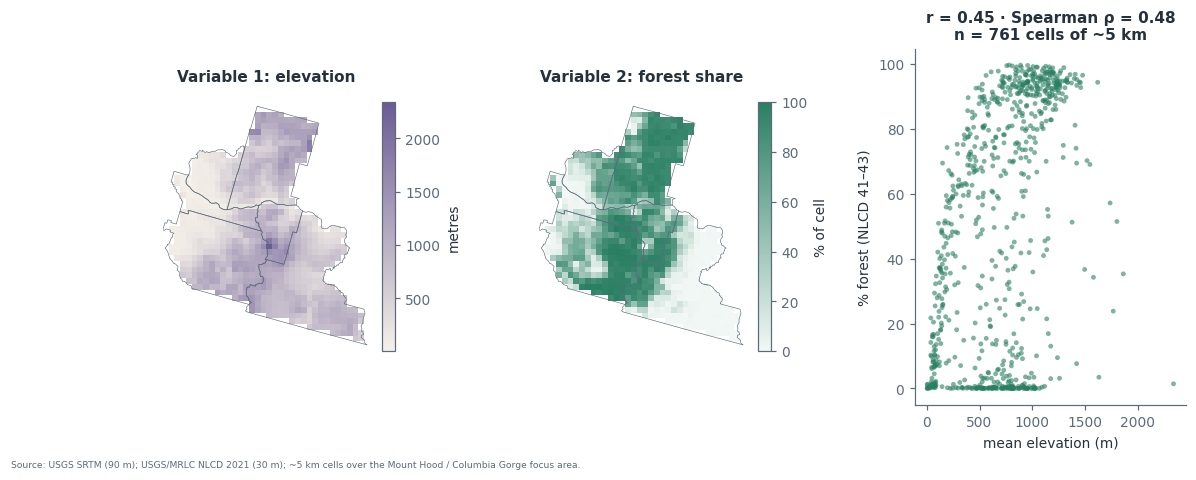

In [14]:
with rasterio.open(RAS8 / "focus_srtm_90m.tif") as src:
    dem, dem_tf = src.read(1, masked=True), src.transform
CELL = 4950.0                                                  # 165 NLCD cells = 55 SRTM cells
gx0, gy1 = lc_tf.c, lc_tf.f


def block_stats(values, valid, tf):
    rows, cols = np.nonzero(valid)
    xs, ys = rasterio.transform.xy(tf, rows, cols)
    gi = ((gy1 - np.asarray(ys)) // CELL).astype(int); gj = ((np.asarray(xs) - gx0) // CELL).astype(int)
    shape = (gi.max() + 1, gj.max() + 1)
    s = np.zeros(shape); c = np.zeros(shape)
    np.add.at(s, (gi, gj), values[rows, cols]); np.add.at(c, (gi, gj), 1)
    return s, c


fs, fc = block_stats(np.isin(lc, FOREST_CODES).astype(float), land, lc_tf)
es, ec = block_stats(dem.filled(0).astype(float), ~dem.mask, dem_tf)
H, Wd = min(fs.shape[0], es.shape[0]), min(fs.shape[1], es.shape[1])
full = fc[:H, :Wd] >= 0.8 * (CELL / 30) ** 2                   # cells at least 80 % inside the focus area
forest_pct = np.where(full, 100 * fs[:H, :Wd] / np.maximum(fc[:H, :Wd], 1), np.nan)
elev = np.where(full, es[:H, :Wd] / np.maximum(ec[:H, :Wd], 1), np.nan)
okc = np.isfinite(forest_pct) & np.isfinite(elev)
r_p, _ = stats.pearsonr(elev[okc], forest_pct[okc]); r_s, _ = stats.spearmanr(elev[okc], forest_pct[okc])
ext = (gx0, gx0 + Wd * CELL, gy1 - H * CELL, gy1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.05], "wspace": 0.45})
im0 = axes[0].imshow(elev, extent=ext, cmap=ramp("#F5F1E8", PAL["purple"]), interpolation="nearest")
fig.colorbar(im0, ax=axes[0], shrink=0.7, label="metres"); axes[0].set_title("Variable 1: elevation")
im1 = axes[1].imshow(forest_pct, extent=ext, cmap=SEQ_GREEN, vmin=0, vmax=100, interpolation="nearest")
fig.colorbar(im1, ax=axes[1], shrink=0.7, label="% of cell"); axes[1].set_title("Variable 2: forest share")
for a in axes[:2]:
    focus.boundary.plot(ax=a, color=PAL["muted"], lw=0.4); a.set_axis_off()
axes[2].scatter(elev[okc], forest_pct[okc], s=10, color=PAL["green"], alpha=0.6, edgecolor="none")
axes[2].set_xlabel("mean elevation (m)"); axes[2].set_ylabel("% forest (NLCD 41–43)")
axes[2].set_title(f"r = {r_p:.2f} · Spearman ρ = {r_s:.2f}\nn = {okc.sum()} cells of ~5 km")
source(fig, "USGS SRTM (90 m); USGS/MRLC NLCD 2021 (30 m); ~5 km cells over the Mount Hood / Columbia Gorge focus area.")
save(fig, "spatial_correlation_two_variables.png", 29)

**Reading the figure**
- **Data:** the focus area cut into ~5 km cells (761 cells at least 80 % inside it); for each cell, mean elevation (SRTM) and % forest (NLCD 41–43).
- **What we did:** mapped the two variables side by side and plotted one against the other, with Pearson r and Spearman ρ.
- **What it shows:** a **moderate positive correlation (r = 0.45, ρ = 0.48)**: higher cells tend to be more forested. The scatter is not one cloud, though — many cells at 500–1,100 m have almost no forest: the dry plateau east of the Cascades (Wasco County), where rainfall rather than elevation limits trees. This is correlation **between two variables**; figure 7 measured autocorrelation of **one**. Neighbouring cells are not independent, so the effective sample is smaller than 761.

### 4.3 Hot and cold spots: Getis-Ord Gi* (slide 26)
Gi\* includes the county itself and asks whether the **local sum** is unusually high or low.

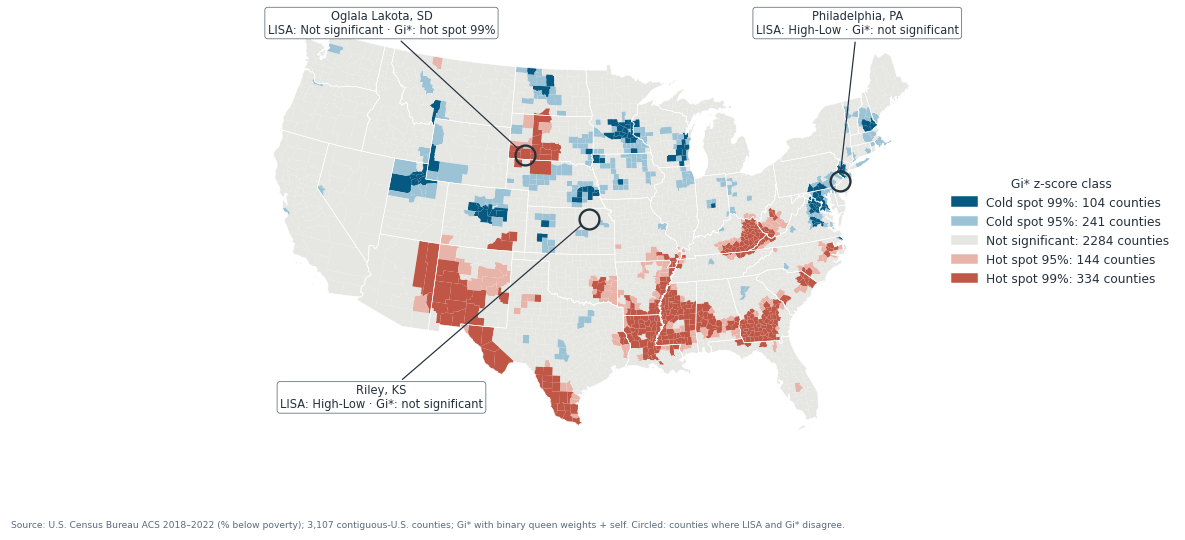

,% below poverty,LISA class,LISA p,Gi* z,Gi* class
county,,,,,
"Riley County, KS",22.7,High-Low,0.045,-0.90,Not significant
"Philadelphia County, PA",22.7,High-Low,0.002,-1.89,Not significant
"Oglala Lakota County, SD",55.8,Not significant,0.054,3.77,Hot spot 99%


gi_class
Cold spot 99%       104
Cold spot 95%       241
Not significant    2284
Hot spot 95%        144
Hot spot 99%        334
Counties both LISA High-High and Gi* hot: 422
Hot spot 99% by state (top 8): {'GA': 59, 'MS': 53, 'KY': 43, 'LA': 36, 'TX': 26, 'AL': 17, 'AR': 16, 'SD': 13}
Cold spot 99% by state (top 8): {'MN': 17, 'VA': 16, 'WI': 11, 'CO': 10, 'NE': 9, 'UT': 7, 'MD': 7, 'NJ': 5}


In [15]:
Wstar = Wb + sparse.eye(n, format="csr")
xv = R.poverty_pct.values
S, Xbar = xv.std(ddof=0), xv.mean()
Wsum = np.asarray(Wstar.sum(axis=1)).ravel()
Gi = ((Wstar @ xv) - Xbar * Wsum) / (S * np.sqrt((n * np.asarray(Wstar.multiply(Wstar).sum(axis=1)).ravel() - Wsum ** 2) / (n - 1)))
GI_NAMES = ["Cold spot 99%", "Cold spot 95%", "Not significant", "Hot spot 95%", "Hot spot 99%"]
GI_COL = dict(zip(GI_NAMES, [PAL["blue"], "#9CC3D5", "#E6E6E3", "#E8B4A9", PAL["terra"]]))
R["gi_class"] = pd.cut(Gi, [-np.inf, -2.58, -1.96, 1.96, 2.58, np.inf], labels=GI_NAMES).astype(str)
gcount = R.gi_class.value_counts().reindex(GI_NAMES, fill_value=0)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
R.plot(ax=ax, color=R.gi_class.map(GI_COL), edgecolor="none")
STATE_LINES.plot(ax=ax, color="white", lw=0.4)
ax.legend([Patch(color=GI_COL[k]) for k in GI_NAMES], [f"{k}: {gcount[k]} {'county' if gcount[k] == 1 else 'counties'}" for k in GI_NAMES],
          loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, title="Gi* z-score class", title_fontsize=8)
ax.set_axis_off()
# Where LISA and Gi* disagree: two High-Low outliers that Gi* cannot show, and the poorest county, which only Gi* flags
DISAGREE = [("Riley County", "KS", (0.20, 0.10)), ("Philadelphia County", "PA", (0.88, 0.95)), ("Oglala Lakota County", "SD", (0.20, 0.95))]   # label positions, axes fraction
rows = []
for name, st, off in DISAGREE:
    c = R[(R.county_label == name) & (R.state_abbr == st)]
    i = c.index[0]; pt = c.geometry.iloc[0].representative_point()
    lab = f"{name.replace(' County', '')}, {st}\nLISA: {R.lisa[i]} · Gi*: {R.gi_class[i].lower()}"
    ax.plot(pt.x, pt.y, "o", ms=13, mfc="none", mec=PAL["ink"], mew=1.5)
    ax.annotate(lab, (pt.x, pt.y), xytext=off, textcoords="axes fraction", fontsize=7.5, color=PAL["ink"], ha="center",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=PAL["muted"], lw=0.5),
                arrowprops=dict(arrowstyle="-", color=PAL["ink"], lw=0.8, shrinkB=7))
    rows.append({"county": f"{name}, {st}", "% below poverty": round(R.poverty_pct[i], 1), "LISA class": R.lisa[i],
                 "LISA p": round(p_loc[i], 3), "Gi* z": round(Gi[i], 2), "Gi* class": R.gi_class[i]})
source(fig, f"U.S. Census Bureau ACS 2018–2022 (% below poverty); {n:,} contiguous-U.S. counties; Gi* with binary queen weights + self. "
            "Circled: counties where LISA and Gi* disagree.")
save(fig, "hotspots_getis_ord.png", 26)
display(pd.DataFrame(rows).set_index("county"))
print(gcount.to_string())
print(f"Counties both LISA High-High and Gi* hot: {((Gi > 1.96) & (R.lisa == 'High-High')).sum()}")
for k in ["Hot spot 99%", "Cold spot 99%"]:
    print(f"{k} by state (top 8):", R[R.gi_class == k].state_abbr.value_counts().head(8).to_dict())

**Reading the figure**
- **Data:** the same 3,107 counties and poverty rates as figure 7.
- **What we did:** Getis-Ord Gi* — for each county, is the sum of its own and its neighbours' rates unusually high (hot spot) or low (cold spot)? z-scores classed at 95 % and 99 % confidence.
- **What it shows:**
  - **478 hot-spot counties** (334 at 99 %): the Mississippi Delta and the Black Belt of Georgia, Alabama and South Carolina, eastern Kentucky, the Texas–Mexico border, the Navajo and Apache lands of Arizona and New Mexico, and the Lakota reservations of South Dakota.
  - **345 cold-spot counties** (104 at 99 %): Minnesota, Wisconsin, Iowa and Nebraska, the Washington DC–Baltimore suburbs, New Hampshire, and the Denver and Salt Lake City areas. 2,284 counties are not significant.
  - Gi* and LISA largely agree here (422 counties are both LISA High-High and Gi* hot) because the clusters are large. They still answer different questions — LISA asks whether a county **resembles** its neighbours, Gi* whether the county-plus-neighbours window is **high or low as a whole**. The **circled counties** show the difference (table above the map):
    - **Riley, KS** and **Philadelphia, PA** (22.7 % each) are LISA **High-Low outliers** — poor counties ringed by richer ones (a large university; a city inside its suburbs). In Gi* their richer neighbours pull the window down, so they are grey: Gi* has no outlier class and they disappear.
    - **Oglala Lakota, SD** (55.8 %, the poorest county in the country) is the reverse: **not significant in LISA** (p = 0.054) but a **99 % Gi* hot spot**. Gi* counts the county's own extreme value inside the window; LISA compares it with random sets of neighbours, and with a value this extreme even random neighbours give a large product.
    - Report which statistic you used: Gi* to delimit a region for intervention, LISA to find the places that break the regional pattern.

### 4.4 Point patterns: clustered, random or dispersed? (slide 27)

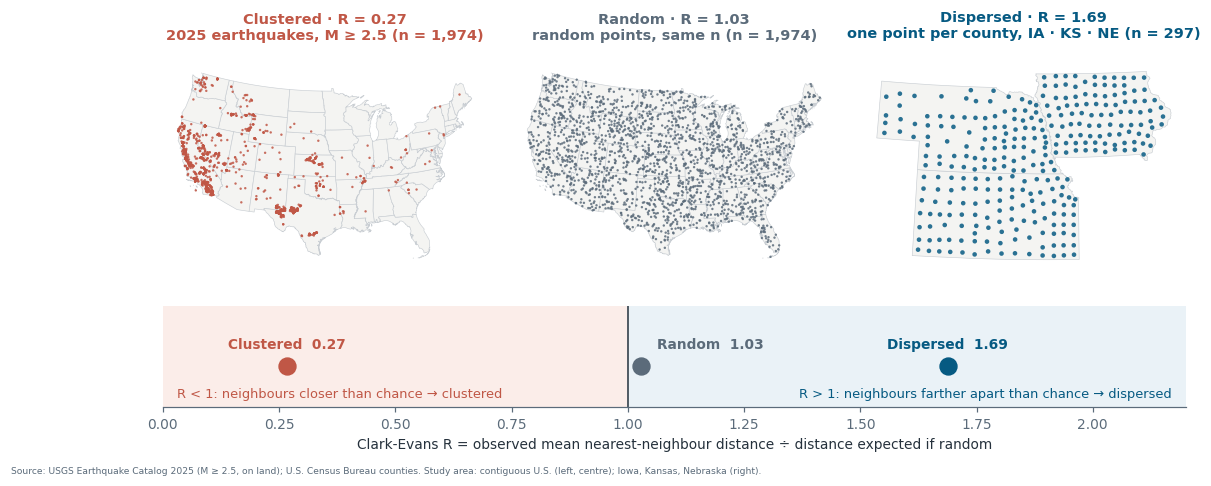

,n,mean NN km,expected if random km,R,z
Clustered,1974.0,8.4,31.4,0.27,-62.3
Random,1974.0,32.4,31.4,1.03,2.5
Dispersed,297.0,36.6,21.7,1.69,22.7


earthquakes by state (top 6): {'CA': 678, 'TX': 488, 'NV': 278, 'ID': 125, 'NM': 74, 'KS': 65} -> 87% of all
CANNOT ESTABLISH: why counties or events cluster. Moran's I and Gi* describe similarity among neighbours under one weights matrix; ~3107 local tests at p < 0.05 without correction expect ~155 false positives; the earthquake pattern also reflects where seismometers are dense, and the CSR test depends on the chosen study area.


In [16]:
quakes = gpd.read_file(VEC / "usgs_earthquakes_2025_m25.shp").to_crs(ALBERS)
region = R.union_all()                                         # contiguous U.S. land = study area for (a) and (b)


def clark_evans(xy, area_m2):
    # mean nearest-neighbour distance, its expectation under complete spatial randomness, R and z
    d = cKDTree(xy).query(xy, k=2)[0][:, 1]
    expected = 0.5 / np.sqrt(len(xy) / area_m2)
    z_score = (d.mean() - expected) / (0.26136 / np.sqrt(len(xy) ** 2 / area_m2))
    return d.mean(), expected, d.mean() / expected, z_score


q = quakes[quakes.within(region)].reset_index(drop=True)
xy_q = np.c_[q.geometry.x, q.geometry.y]

csr_rng = np.random.default_rng(34)                            # own generator, so §5 is unchanged
x0, y0, x1, y1 = region.bounds
cand = csr_rng.uniform([x0, y0], [x1, y1], size=(len(q) * 4, 2))
xy_r = cand[shapely.contains_xy(region, cand[:, 0], cand[:, 1])][:len(q)]   # same n, uniform over the same land
assert len(xy_r) == len(q)

plains = R[R.state_abbr.isin(["IA", "KS", "NE"])]               # near-regular county grid of the Great Plains
pts_c = plains.representative_point()                          # one point inside every county
xy_c = np.c_[pts_c.x, pts_c.y]

STATES = R.dissolve("state_abbr")
PATTERNS = [("Clustered", "2025 earthquakes, M ≥ 2.5", xy_q, region, STATES, 2.5, PAL["terra"]),
            ("Random", "random points, same n", xy_r, region, STATES, 2.5, PAL["muted"]),
            ("Dispersed", "one point per county, IA · KS · NE", xy_c, plains.union_all(), STATES.loc[["IA", "KS", "NE"]], 9, PAL["blue"])]
ce = {name: clark_evans(xy, area.area) for name, _, xy, area, *_ in PATTERNS}

fig = plt.figure(figsize=(12, 4.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.36], hspace=0.0, wspace=0.08)
for k, (name, what, xy, _, base, size, col) in enumerate(PATTERNS):
    ax = fig.add_subplot(gs[0, k])
    base.plot(ax=ax, color="#F4F4F2", edgecolor="#C9CED3", lw=0.4)
    ax.scatter(xy[:, 0], xy[:, 1], s=size, color=col, alpha=0.85, edgecolor="none")
    ax.set_title(f"{name} · R = {ce[name][2]:.2f}\n{what} (n = {len(xy):,})", color=col, fontsize=9.5)
    ax.set_axis_off()
ax = fig.add_subplot(gs[1, :])
ax.axvspan(0, 1, color="#FBEDE9"); ax.axvspan(1, 2.2, color="#EAF2F7")
ax.axvline(1, color=PAL["ink"], lw=1)
for name, *_, col in PATTERNS:
    ax.plot(ce[name][2], 0.5, "o", ms=11, color=col)
    ax.annotate(f"{name}  {ce[name][2]:.2f}", (ce[name][2], 0.5), xytext=(10 if name == "Random" else 0, 10),
                textcoords="offset points", ha="left" if name == "Random" else "center", va="bottom", fontsize=9, fontweight="bold", color=col)
ax.text(0.03, 0.12, "R < 1: neighbours closer than chance → clustered", fontsize=8.5, color=PAL["terra"])
ax.text(2.17, 0.12, "R > 1: neighbours farther apart than chance → dispersed", fontsize=8.5, color=PAL["blue"], ha="right")
ax.set_xlim(0, 2.2); ax.set_ylim(0, 1.25); ax.set_yticks([])
ax.set_xlabel("Clark-Evans R = observed mean nearest-neighbour distance ÷ distance expected if random")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
source(fig, "USGS Earthquake Catalog 2025 (M ≥ 2.5, on land); U.S. Census Bureau counties. Study area: contiguous U.S. (left, centre); Iowa, Kansas, Nebraska (right).")
save(fig, "point_pattern_nn.png", 27)
display(pd.DataFrame({name: {"n": len(xy), "mean NN km": round(ce[name][0] / 1000, 1),
                             "expected if random km": round(ce[name][1] / 1000, 1),
                             "R": round(ce[name][2], 2), "z": round(ce[name][3], 1)}
                      for name, _, xy, *_ in PATTERNS}).T)
q_state = gpd.sjoin(q[["geometry"]], R[["state_abbr", "geometry"]], predicate="within").state_abbr.value_counts()
print("earthquakes by state (top 6):", q_state.head(6).to_dict(), f"-> {q_state.head(6).sum() / len(q):.0%} of all")
cannot("why counties or events cluster. Moran's I and Gi* describe similarity among neighbours under one weights "
       f"matrix; ~{n} local tests at p < 0.05 without correction expect ~{round(0.05 * n)} false positives; the "
       "earthquake pattern also reflects where seismometers are dense, and the CSR test depends on the chosen study area.")

**Reading the figure**
- **Data:** three point layers. *Left*: the 1,974 USGS earthquakes of magnitude ≥ 2.5 recorded on land in the contiguous U.S. in 2025. *Centre*: 1,974 points scattered completely at random over the same land (simulated). *Right*: one point inside each of the 297 counties of Iowa, Kansas and Nebraska.
- **What we did:** for every point, measured the distance to its nearest other point, averaged it, and divided by the average expected if the same number of points were scattered at random over the same area (Clark-Evans ratio R; the table above lists the distances and z-scores). The bar at the bottom places the three R values on one scale.
- **What it shows:**
  - **Clustered, R = 0.27:** earthquakes sit 8.4 km from their nearest neighbour on average, against 31.4 km if random. 87 % of them fall in six states (California 678, Texas 488, Nevada 278, Idaho 125, New Mexico 74, Kansas 65): along the plate boundary in California and Nevada, and in oil-and-gas fields of West Texas, New Mexico and Kansas, where much of the shaking is linked to wastewater injection.
  - **Random, R = 1.03:** close to 1, as it should be. It is slightly above 1 (z = 2.5) because this simple test makes no correction for the border: points near the coast or the national border have no neighbours on one side, so their nearest neighbour is a little farther away. Read R values near 1 with that in mind.
  - **Dispersed, R = 1.69:** Plains counties were surveyed as a near-regular grid, so their points keep their distance from each other — 36.6 km apart against 21.7 km if random.
  - The same R statistic separates the three patterns; the maps make the meaning of "R < 1" and "R > 1" visible.

---
## 5 · Remote Sensing and Machine Learning  (slides 30–37) · **LO 3**
GIS starts from objects; remote sensing starts from a **signal**. The pipeline below — reflectance → index → classified objects — is the poverty-from-space workflow (slide 37) in miniature, on the **Sentinel-2** scene of Champaign–Urbana from the Week 7 pack (4 bands, 10 m, summer 2023), with **NLCD 2021** as training labels.

In [17]:
with rasterio.open(RAS / "champaign_sentinel2_2023_10m.tif") as src:
    s2 = src.read().astype("float32") / 10000.0
    s2_tf, s2_crs, s2_ext = src.transform, src.crs, plotting_extent(src)
red, green, blue, nir = s2
ndvi = (nir - red) / (nir + red + 1e-9)


def stretch(bands, lo=2, hi=98):
    out = []
    for b in bands:
        p1, p2 = np.percentile(b, [lo, hi]); out.append(np.clip((b - p1) / (p2 - p1 + 1e-9), 0, 1))
    return np.dstack(out)


from rasterio.warp import reproject, Resampling
with rasterio.open(RAS / "illinois_landcover_nlcd2021_150m.tif") as src:
    labels = np.zeros(s2.shape[1:], dtype="uint8")
    reproject(rasterio.band(src, 1), labels, src_transform=src.transform, src_crs=src.crs,
              dst_transform=s2_tf, dst_crs=s2_crs, resampling=Resampling.nearest)
    CH_CMAP = {k: tuple(c / 255 for c in v) for k, v in src.colormap(1).items()}
CH_LABEL = dict(pd.read_csv(RAS / "nlcd_classes.csv").values)

X = np.stack([red, green, blue, nir, ndvi], -1).reshape(-1, 5)
yv = labels.ravel()
usable = (yv > 0) & np.isfinite(X).all(axis=1)
vc = pd.Series(yv[usable]).value_counts()
classes = sorted(vc[vc >= 2000].index)
usable &= np.isin(yv, classes)
idx = RNG.choice(np.flatnonzero(usable), size=min(120_000, usable.sum()), replace=False)
Xtr, Xte, ytr, yte = train_test_split(X[idx], yv[idx], test_size=0.3, random_state=570, stratify=yv[idx])
rf = RandomForestClassifier(n_estimators=120, min_samples_leaf=5, n_jobs=-1, random_state=570).fit(Xtr, ytr)
pred = rf.predict(Xte)
acc = accuracy_score(yte, pred)
full = rf.predict(np.nan_to_num(X)).reshape(labels.shape)
print(f"train {len(Xtr):,} / test {len(Xte):,} pixels · {len(classes)} classes · overall accuracy {acc:.3f}")

train 84,000 / test 36,000 pixels · 11 classes · overall accuracy 0.684


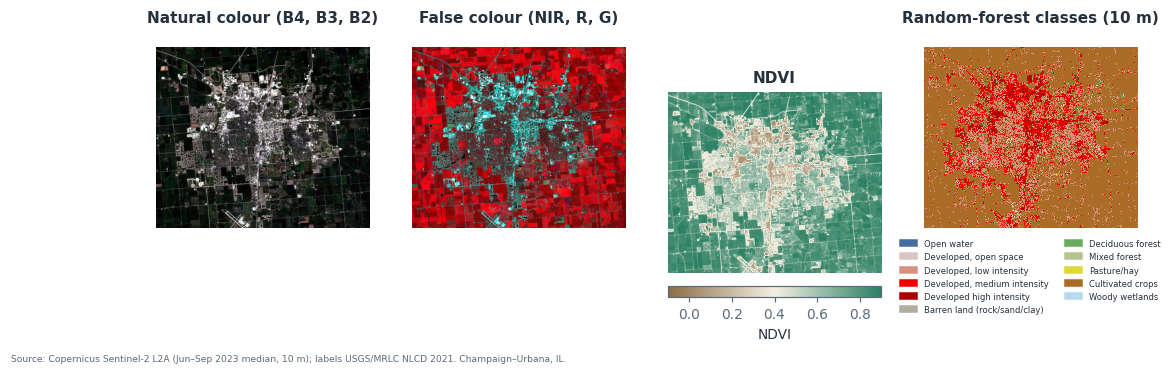

In [18]:
lut = np.ones((256, 4))
for c in classes:
    lut[c] = CH_CMAP[c]
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.9))
axes[0].imshow(stretch([red, green, blue]), extent=s2_ext); axes[0].set_title("Natural colour (B4, B3, B2)")
axes[1].imshow(stretch([nir, red, green]), extent=s2_ext); axes[1].set_title("False colour (NIR, R, G)")
im = axes[2].imshow(ndvi, extent=s2_ext, cmap=ramp("#8C6D46", "#F3EFE2", PAL["green"]), vmin=-0.1, vmax=0.9)
fig.colorbar(im, ax=axes[2], orientation="horizontal", fraction=0.05, pad=0.04, label="NDVI"); axes[2].set_title("NDVI")
axes[3].imshow(lut[full], extent=s2_ext, interpolation="nearest"); axes[3].set_title("Random-forest classes (10 m)")
axes[3].legend([Patch(color=CH_CMAP[c]) for c in classes], [CH_LABEL[c] for c in classes], fontsize=5.5, ncol=2,
               loc="upper center", bbox_to_anchor=(0.5, -0.02))
for a in axes:
    a.set_axis_off()
source(fig, "Copernicus Sentinel-2 L2A (Jun–Sep 2023 median, 10 m); labels USGS/MRLC NLCD 2021. Champaign–Urbana, IL.")
save(fig, "rs_ndvi_classification.png", 32)

**Reading the figure**
- **Data:** a Sentinel-2 summer-2023 composite of Champaign–Urbana, IL (10 m; red, green, blue and near-infrared bands) and NLCD 2021 land cover as training labels.
- **What we did:** (1) natural colour; (2) false colour, with near-infrared shown as red; (3) NDVI = (NIR − red)/(NIR + red); (4) a random-forest classification of every pixel.
- **What the model was given:**
  - **Input (features), one row per 10 m pixel, 5 numbers:** surface reflectance in red (B4), green (B3), blue (B2) and near-infrared (B8) — the file stores reflectance × 10,000, the notebook divides by 10,000 — plus NDVI computed from B8 and B4.
  - **Label (target):** the NLCD 2021 class code of the same location (e.g. 82 = cultivated crops, 21–24 = developed). The label raster is the Week 7 NLCD at **150 m**, resampled by nearest neighbour onto the 10 m Sentinel-2 grid, so each label is a 15 × 15-pixel block; classes with fewer than 2,000 pixels in the scene were dropped (11 classes kept).
  - **Samples:** 120,000 randomly chosen labelled pixels, split 70 / 30 (84,000 training, 36,000 test), stratified by class. No hand-drawn training polygons: the labels come from an existing map, which is why §5 calls NLCD "treated as truth".
- **What it shows:** vegetation reflects strongly in near-infrared, so crops turn bright red in (2) and green in (3), while the city stands out with low NDVI. The classifier reproduces the broad pattern — urban core vs cropland — but figure 12 shows how often it is right, class by class.

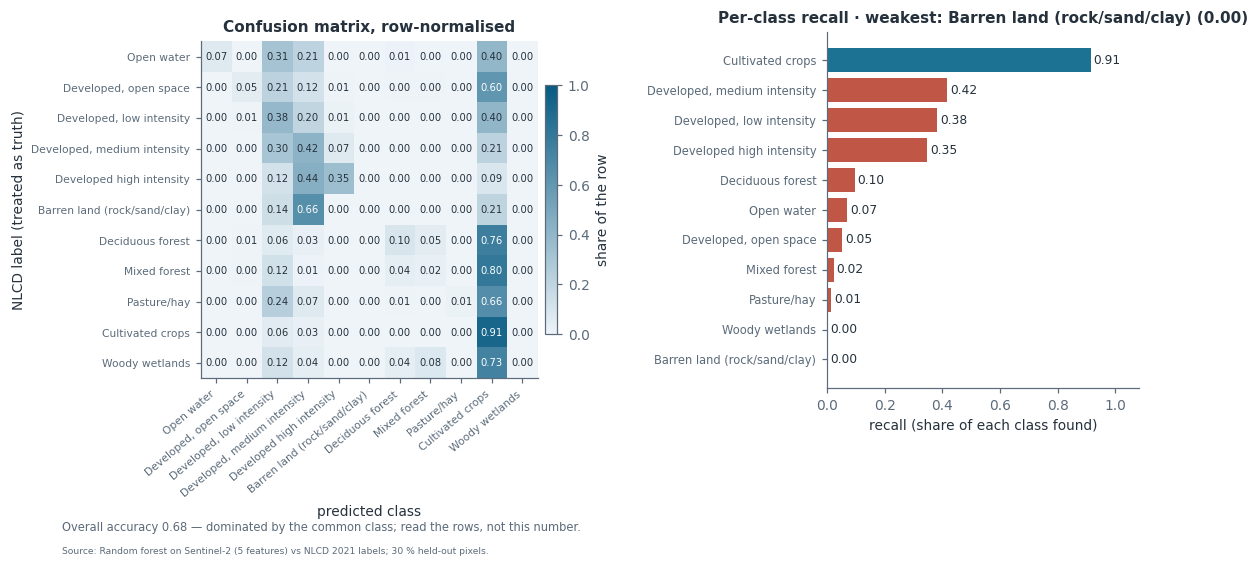

,recall,test pixels
Barren land (rock/sand/clay),0.000,29
Woody wetlands,0.000,26
Pasture/hay,0.015,550
Mixed forest,0.023,220
"Developed, open space",0.053,1241
Open water,0.070,86
Deciduous forest,0.096,187
Developed high intensity,0.347,1416
"Developed, low intensity",0.381,5962
"Developed, medium intensity",0.416,4591


CANNOT ESTABLISH: how well the model sees the ground. It reproduces another classification (NLCD at 150 m) from 10 m pixels, so some 'errors' belong to the labels; one scene and one season; accuracy depends on which classes were kept.


In [19]:
cm = confusion_matrix(yte, pred, labels=classes)
cmn = cm / cm.sum(axis=1, keepdims=True)
names = [CH_LABEL[c] for c in classes]
recall = pd.Series(cm.diagonal() / cm.sum(axis=1), index=names).sort_values()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.8})
im = a1.imshow(cmn, cmap=SEQ_BLUE, vmin=0, vmax=1)
a1.set_xticks(range(len(classes)), names, rotation=40, ha="right", fontsize=7)
a1.set_yticks(range(len(classes)), names, fontsize=7)
a1.set_xlabel("predicted class"); a1.set_ylabel("NLCD label (treated as truth)")
for r in range(len(classes)):
    for c in range(len(classes)):
        a1.text(c, r, f"{cmn[r, c]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if cmn[r, c] > 0.55 else PAL["ink"])
fig.colorbar(im, ax=a1, shrink=0.7, fraction=0.04, pad=0.02, label="share of the row")
a1.set_title("Confusion matrix, row-normalised")
cols = [PAL["terra"] if v < 0.5 else PAL["teal"] for v in recall]
a2.barh(recall.index, recall.values, color=cols)
for k, v in enumerate(recall.values):
    a2.text(v + 0.01, k, f"{v:.2f}", va="center", fontsize=8)
a2.set_xlim(0, 1.08); a2.set_xlabel("recall (share of each class found)"); a2.tick_params(axis="y", labelsize=7.5)
a2.set_title(f"Per-class recall · weakest: {recall.index[0]} ({recall.iloc[0]:.2f})")
fig.text(0.01, -0.2, f"Overall accuracy {acc:.2f} — dominated by the common class; read the rows, not this number.",
         fontsize=7.5, color=PAL["muted"])
fig.text(0.01, -0.235, "Source: Random forest on Sentinel-2 (5 features) vs NLCD 2021 labels; 30 % held-out pixels.",
         fontsize=6, color=PAL["muted"], va="top")
save(fig, "ml_confusion_matrix.png", 36)
display(pd.DataFrame({"recall": recall.round(3), "test pixels": pd.Series(cm.sum(axis=1), index=names)}).sort_values("recall"))
cannot("how well the model sees the ground. It reproduces another classification (NLCD at 150 m) from 10 m pixels, "
       "so some 'errors' belong to the labels; one scene and one season; accuracy depends on which classes were kept.")

**Reading the figure**
- **Data:** 36,000 test pixels the model never saw during training, each with its NLCD label and the model's prediction.
- **What we did:** a row-normalised confusion matrix (each row = one true class; the cells show where its pixels were predicted to go) and the recall of each class (share of that class found).
- **What it shows:** overall accuracy is **0.68**, but **60 % of the test pixels are cultivated crops** (recall 0.91), and they carry the score. Developed classes are found 33–44 % of the time, forests 3–14 %, woody wetlands and barren land never; most minority pixels are predicted as crops (the dark column). Part of the "error" belongs to the labels: NLCD here is 150 m, the image 10 m.

---
## 6 · Policy and the Politics of Categories  (slides 38–43) · **LO 4**
Robbins (2001): land-cover categories are **decisions that become infrastructure**. Three demonstrations.

### 6.1 Who defines "forest" — and "protected"? (slide 40)

,km²,% of focus area
Canopy in blocks ≥ 1 km²,9232.9,46.8
"Canopy, FAO minimum 0.5 ha",9834.2,49.9
"Canopy (NLCD 41, 42, 43)",9860.5,50.0
+ woody wetlands (90),10035.0,50.9
+ shrub/scrub (52): 'other wooded land',12010.2,60.9


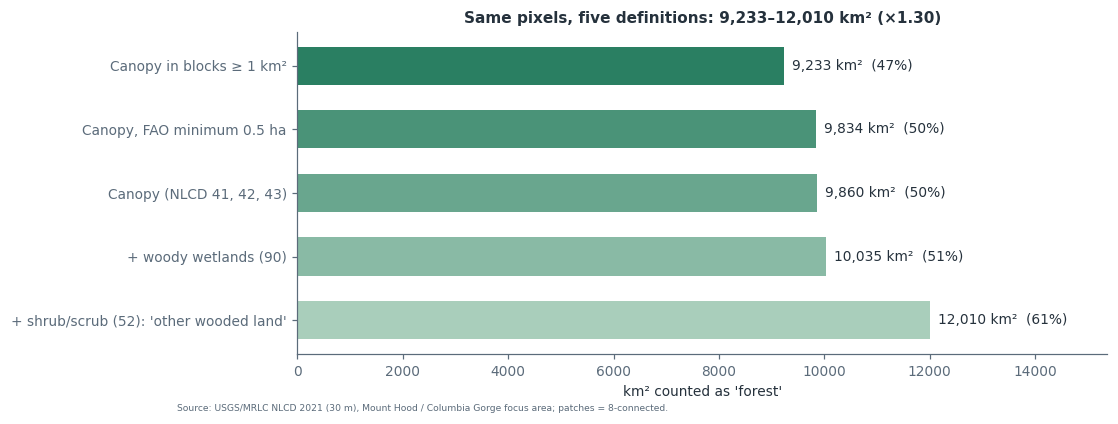

,km² (dissolved),% of focus area
definition of 'protected',,
GAP 1 only (wilderness-like),1425.3,7.2
GAP 1–2 (managed for biodiversity),2085.1,10.6
GAP 1–3 (+ multiple use),9774.3,49.5
any PAD-US record (GAP 1–4),9976.7,50.6


In [20]:
def patch_filter(mask, min_km2):
    lab, _ = ndimage.label(mask, structure=np.ones((3, 3)))
    sizes = np.bincount(lab.ravel()) * CELL_KM2; sizes[0] = 0
    return (sizes >= min_km2)[lab]


canopy = np.isin(lc, FOREST_CODES) & land
DEFS = {
    "Canopy in blocks ≥ 1 km²": patch_filter(canopy, 1.0),
    "Canopy, FAO minimum 0.5 ha": patch_filter(canopy, 0.005),
    "Canopy (NLCD 41, 42, 43)": canopy,
    "+ woody wetlands (90)": np.isin(lc, FOREST_CODES + [90]) & land,
    "+ shrub/scrub (52): 'other wooded land'": np.isin(lc, FOREST_CODES + [90, 52]) & land,
}
land_km2 = land.sum() * CELL_KM2
fd = pd.DataFrame({"km²": {k: m.sum() * CELL_KM2 for k, m in DEFS.items()}})
fd["% of focus area"] = 100 * fd["km²"] / land_km2
display(fd.round(1))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
colours = [ramp("#BFDCCB", PAL["green"])(t) for t in np.linspace(1, 0.15, len(fd))]
ax.barh(fd.index, fd["km²"], color=colours, height=0.6)
for k, (v, p) in enumerate(zip(fd["km²"], fd["% of focus area"])):
    ax.text(v + land_km2 * 0.008, k, f"{v:,.0f} km²  ({p:.0f}%)", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, fd["km²"].max() * 1.28); ax.set_xlabel("km² counted as 'forest'")
ax.set_title(f"Same pixels, five definitions: {fd['km²'].min():,.0f}–{fd['km²'].max():,.0f} km² "
             f"(×{fd['km²'].max() / fd['km²'].min():.2f})")
source(fig, "USGS/MRLC NLCD 2021 (30 m), Mount Hood / Columbia Gorge focus area; patches = 8-connected.")
save(fig, "categories_forest_definitions.png", 40)

prot = pd.DataFrame({"definition of 'protected'": ["GAP 1 only (wilderness-like)", "GAP 1–2 (managed for biodiversity)",
                                                   "GAP 1–3 (+ multiple use)", "any PAD-US record (GAP 1–4)"],
                     "km² (dissolved)": [pad[pad.GAP <= g].union_all().area / 1e6 for g in (1, 2, 3, 4)]})
prot["% of focus area"] = 100 * prot["km² (dissolved)"] / (focus.area.sum() / 1e6)
display(prot.round(1).set_index("definition of 'protected'"))

**Reading the figure**
- **Data:** NLCD 2021 at 30 m for the focus area (about 19,700 km² of land), and PAD-US for "protected".
- **What we did:** counted forest area under five defensible definitions — canopy classes 41–43; the same, dropping patches below FAO's 0.5 ha minimum or below 1 km²; adding woody wetlands (90); adding shrub/scrub (52, FAO's "other wooded land"). The second table does the same for "protected", from GAP 1 only to any PAD-US record.
- **What it shows:** forest ranges from **9,233 to 12,010 km² (× 1.30) without a single pixel changing**; the shrub rule alone adds about 1,975 km². "Protected" ranges from 1,425 km² (GAP 1, 7.2 % of the area) to 9,977 km² (any record, 50.6 %) — a factor of 7. The category is a choice with consequences (Robbins).

### 6.2 MAUP: the same events, two aggregations (slide 41)

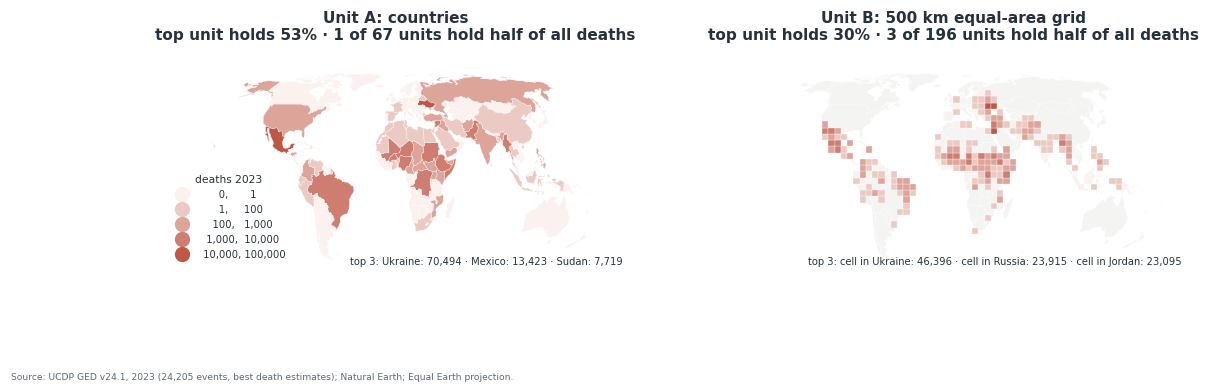

countries: top 53.3%, 1 units hold half | 500 km cells: top 30.0%, 3 units hold half


In [21]:
ged = pd.read_csv(TAB / "ucdp_ged_events_2023.csv")
ged_pts = gpd.GeoDataFrame(ged, geometry=gpd.points_from_xy(ged.longitude, ged.latitude), crs=4326)
wmap = world[world.CONTINENT != "Antarctica"].to_crs(8857)
gp = ged_pts.to_crs(8857)
by_country = gpd.sjoin(gp, wmap[["NAME", "geometry"]], predicate="within", how="inner").groupby("NAME").deaths_best.sum()
GRID = 500_000
gx, gy = np.floor(gp.geometry.x / GRID).astype(int), np.floor(gp.geometry.y / GRID).astype(int)
by_cell = gp.assign(gx=gx, gy=gy).groupby(["gx", "gy"]).deaths_best.sum()
cells = gpd.GeoDataFrame({"deaths": by_cell.values},
                         geometry=[box(a * GRID, b * GRID, (a + 1) * GRID, (b + 1) * GRID) for a, b in by_cell.index], crs=8857)


def concentration(s):
    s = s.sort_values(ascending=False)
    return 100 * s.iloc[0] / s.sum(), int((s.cumsum() / s.sum() < 0.5).sum() + 1), len(s)


cc, cg = concentration(by_country), concentration(by_cell)
top_c = by_country.sort_values(ascending=False).head(3)
cells_rank = cells.sort_values("deaths", ascending=False).head(3)
cells_rank_names = [gpd.sjoin(gpd.GeoDataFrame(geometry=[g.centroid], crs=8857), wmap[["NAME", "geometry"]],
                              predicate="within", how="left").NAME.iloc[0] for g in cells_rank.geometry]
bins = [1, 100, 1000, 10000, 100000]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
wmap.plot(ax=axes[0], column=wmap.NAME.map(by_country).fillna(0), cmap=SEQ_TERRA, scheme="UserDefined",
          classification_kwds={"bins": bins}, edgecolor="white", lw=0.2, legend=True,
          legend_kwds={"fmt": "{:,.0f}", "loc": "lower left", "fontsize": 6.5, "title": "deaths 2023", "title_fontsize": 7})
wmap.plot(ax=axes[1], color="#F4F4F2", edgecolor="white", lw=0.2)
cells.plot(ax=axes[1], column="deaths", cmap=SEQ_TERRA, scheme="UserDefined", classification_kwds={"bins": bins},
           edgecolor="white", lw=0.2)
for ax, (share, k50, nu), ttl, tops in [
        (axes[0], cc, "Unit A: countries", [f"{n_}: {v:,.0f}" for n_, v in top_c.items()]),
        (axes[1], cg, "Unit B: 500 km equal-area grid", [f"cell in {n_}: {v:,.0f}" for n_, v in zip(cells_rank_names, cells_rank.deaths)])]:
    ax.set_title(f"{ttl}\ntop unit holds {share:.0f}% · {k50} of {nu} units hold half of all deaths")
    ax.text(0.99, 0.02, "top 3: " + " · ".join(tops), transform=ax.transAxes, ha="right", fontsize=6.5, color=PAL["ink"])
    ax.set_axis_off()
source(fig, "UCDP GED v24.1, 2023 (24,205 events, best death estimates); Natural Earth; Equal Earth projection.")
save(fig, "maup_two_aggregations.png", 41)
print(f"countries: top {cc[0]:.1f}%, {cc[1]} units hold half | 500 km cells: top {cg[0]:.1f}%, {cg[1]} units hold half")

**Reading the figure**
- **Data:** the 24,205 UCDP conflict events of 2023 worldwide, with their best-estimate deaths.
- **What we did:** summed the deaths two ways — by country (left) and by 500 km × 500 km equal-area grid cell (right) — and for each measured how concentrated the violence looks: the share held by the top unit, and how many units hold half of all deaths.
- **What it shows:** by country, **Ukraine alone holds 53 % of deaths and 1 of 67 countries holds half**; by grid cell the top cell holds 30 % and it takes **3 of 196 cells** to reach half. The ranking changes too (countries: Ukraine, Mexico, Sudan; cells: Ukraine, Russia, Jordan — cells are named by the country at their centre, so the "Jordan" cell also covers neighbouring areas). Same events, different units, different story: the MAUP.

### 6.3 Ethics: exact points vs an aggregated rate (slide 43)

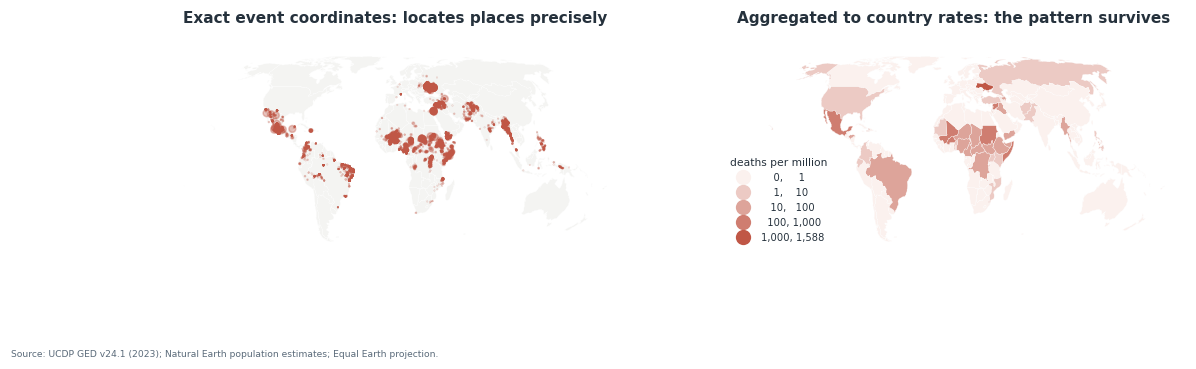

CANNOT ESTABLISH: which aggregation is 'correct' — the MAUP has no neutral unit — or that the aggregated map is harmless; small countries can still be re-identified. The forest and protected areas above change by definition alone, so any target or subsidy built on them inherits that choice.


In [22]:
wc = wmap.copy()
wc["deaths"] = wc.NAME.map(by_country).fillna(0)
wc["per_million"] = wc.deaths / wc.POP_EST.replace(0, np.nan) * 1e6
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
wmap.plot(ax=axes[0], color="#F4F4F2", edgecolor="white", lw=0.2)
gp.plot(ax=axes[0], markersize=np.clip(ged.deaths_best, 1, 300) / 15, color=PAL["terra"], alpha=0.35)
axes[0].set_title("Exact event coordinates: locates places precisely")
wc.plot(ax=axes[1], column="per_million", cmap=SEQ_TERRA, scheme="UserDefined", classification_kwds={"bins": [1, 10, 100, 1000, float(wc.per_million.max())]},
        edgecolor="white", lw=0.2, legend=True, missing_kwds=MISSING,
        legend_kwds={"fmt": "{:,.0f}", "loc": "lower left", "fontsize": 6.5, "title": "deaths per million", "title_fontsize": 7})
axes[1].set_title("Aggregated to country rates: the pattern survives")
for a in axes:
    a.set_axis_off()
source(fig, "UCDP GED v24.1 (2023); Natural Earth population estimates; Equal Earth projection.")
save(fig, "ethics_point_vs_aggregated.png", 43)
cannot("which aggregation is 'correct' — the MAUP has no neutral unit — or that the aggregated map is harmless; "
       "small countries can still be re-identified. The forest and protected areas above change by definition alone, "
       "so any target or subsidy built on them inherits that choice.")

**Reading the figure**
- **Data:** the same 24,205 events; country populations from Natural Earth.
- **What we did:** *left* — every event at its exact coordinates, dot size by deaths; *right* — deaths per million people by country.
- **What it shows:** both maps highlight the same regions (Ukraine, the Sahel and Sudan, Myanmar, Mexico), so aggregating costs almost nothing for the policy picture — while the left map locates places where people were killed precisely enough to be misused.

---
## 7 · Discussion and AI Engagement  (slides 44–46)
**Who defines the categories?** Use §6.1: the focus area has between the smallest and the largest forest figure without a pixel changing, and strict protection covers a fraction of what "any PAD-US record" suggests. If a plot is "degraded forest" rather than "pastoral commons", who gains and who loses?

**AI task.** Prompt an AI for an **analysis** (not a map) with the brief below, then compare it with your own on three points: did it justify the buffer distance, state the unit and the MAUP risk, and name a limit?

In [23]:
BRIEF = '''
Propose a spatial analysis for [policy question], using [layers], at [unit of analysis].
OPERATION — overlay (which of clip/intersect/erase/union/identity), buffer, proximity or cluster detection; what each assumes.
  If a buffer: give the distance AND justify it; show the result at two other distances.
  If clustering: name the statistic, the weights and the null model.
DATA AND UNITS — CRS (equal-area for areas, metres for distances; EPSG code); unit of analysis and its MAUP risk;
  counts, per-capita rates or per-km² densities, and why.
OUTPUT AND LIMITS — one sentence of interpretation and one sentence on what the analysis CANNOT establish;
  whether the output locates vulnerable people precisely (if so, aggregate first).
DO NOT — report a p-value without the null model, an accuracy without per-class results, or invent a layer.
'''
print(BRIEF)


Propose a spatial analysis for [policy question], using [layers], at [unit of analysis].
OPERATION — overlay (which of clip/intersect/erase/union/identity), buffer, proximity or cluster detection; what each assumes.
  If a buffer: give the distance AND justify it; show the result at two other distances.
  If clustering: name the statistic, the weights and the null model.
DATA AND UNITS — CRS (equal-area for areas, metres for distances; EPSG code); unit of analysis and its MAUP risk;
  counts, per-capita rates or per-km² densities, and why.
OUTPUT AND LIMITS — one sentence of interpretation and one sentence on what the analysis CANNOT establish;
  whether the output locates vulnerable people precisely (if so, aggregate first).
DO NOT — report a p-value without the null model, an accuracy without per-class results, or invent a layer.



---
## 8 · Lab and Deliverable  (slides 47–49) · **LO 5**
| Time | Step (slide 48) | QGIS |
|---|---|---|
| 0–15′ | Overlay: forest × protected areas; measure the gap | `focus_nlcd2021_30m.tif` → *Raster ▸ Conversion ▸ Polygonize* (or reclassify), `padus41_mthood_gorge.shp` filtered `"GAP_Sts" <= '2'` → *Vector ▸ Geoprocessing ▸ Intersection / Difference* |
| 15–30′ | Buffer around conflict events; which camps fall inside? | `ucdp_ged_2023_near_camps.csv` (*Add Delimited Text Layer*, EPSG:4326) → reproject to EPSG:32646 → *Buffer* at two distances → *Select by Location* on `coxsbazar_camps_2023.shp` |
| 30–40′ | Pick one: a spatial statistic · Earth Engine task · OSINT overlay | GeoDa on `us_counties_acs2022.shp` (Moran/LISA); or `ucdp_ged_events_2023.csv` aggregated by country |
| 40–55′ | Export maps; write the memo | *Project ▸ New Print Layout* |

**Deliverable (slide 49):** exported map(s) + a 200–300-word memo with **one policy implication**; optional OSINT and AI reflections.

In [24]:
memo = f'''# Week 8 workflow memo

## Question
[One sentence: what policy question does this analysis answer?]

## Data and units
- Focus area: {", ".join(sorted(focus.NAME))} ({len(focus)} counties), EPSG:{ALBERS} (equal-area, metres)
- Forest: NLCD 2021, 30 m, classes {FOREST_CODES}. Five other defensible definitions give {fd["km²"].min():,.0f}–{fd["km²"].max():,.0f} km² (§6.1).
- Protected areas: PAD-US 4.1, GAP status 1–2 = "protected" here; GAP 1–3 would change the answer (§2.4).

## Operations and results
1. Overlay: {pct12:.1f}% of forest is inside GAP 1–2 ({P12:,.0f} of {F_km2:,.0f} km²); {pct123:.1f}% inside GAP 1–3.
2. Buffer: {min(share1):.0f}%–{max(share1):.0f}% of the 33 Cox's Bazar camps are "near conflict" for radii {RADII[0]}–{RADII[-1]} km.
3. Clustering: Moran's I = {moran_I:.3f} (pseudo p = {p_moran:.3f}, queen weights, 999 permutations, {n:,} contiguous-U.S. counties).
4. Classification: overall accuracy {acc:.2f}; weakest class {recall.index[0]} (recall {recall.iloc[0]:.2f}).

## One policy implication
[What should change, for whom, on the strength of this?]

## What this analysis cannot establish
[Correlation vs mechanism; designation vs outcome; Euclidean vs travel distance; MAUP; label quality.]

## AI engagement / Ethics
[What did the AI propose, and what did it fill in silently? Does any output locate vulnerable people precisely?]
'''
(OUT / "week8_workflow_memo.md").write_text(memo)
print(memo)

gpkg = OUT / "week8_outputs.gpkg"
gpkg.unlink(missing_ok=True)                                   # rewrite from scratch: no stale layers from older runs
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, g in [("forest_protected_gap12", inside12), ("forest_gap", gap_forest), ("padus_dissolved_by_gap", diss),
                    ("camps_distance_to_conflict", camps), ("us_counties_clusters", R.assign(gi_z=Gi, local_I=Ii, p_local=p_loc)[
                        ["geoid", "county_label", "state_abbr", "poverty_pct", "lisa", "gi_class", "gi_z", "local_I", "p_local", "geometry"]])]:
        g.to_file(gpkg, layer=name, driver="GPKG")
print("QGIS layers written to", gpkg)

# Week 8 workflow memo

## Question
[One sentence: what policy question does this analysis answer?]

## Data and units
- Focus area: Clackamas, Clark, Hood River, Multnomah, Skamania, Wasco (6 counties), EPSG:5070 (equal-area, metres)
- Forest: NLCD 2021, 30 m, classes [41, 42, 43]. Five other defensible definitions give 9,233–12,010 km² (§6.1).
- Protected areas: PAD-US 4.1, GAP status 1–2 = "protected" here; GAP 1–3 would change the answer (§2.4).

## Operations and results
1. Overlay: 14.0% of forest is inside GAP 1–2 (1,377 of 9,860 km²); 73.3% inside GAP 1–3.
2. Buffer: 64%–100% of the 33 Cox's Bazar camps are "near conflict" for radii 1–100 km.
3. Clustering: Moran's I = 0.496 (pseudo p = 0.001, queen weights, 999 permutations, 3,107 contiguous-U.S. counties).
4. Classification: overall accuracy 0.68; weakest class Barren land (rock/sand/clay) (recall 0.00).

## One policy implication
[What should change, for whom, on the strength of this?]

## What this analysis cannot establish

QGIS layers written to outputs/week8_outputs.gpkg


### Figure checklist and headline numbers

In [25]:
EXPECTED = {"spatial_shuffle_test.png": 10,
            "overlay_operations.png": 13,
            "overlay_policy_forest_protected.png": 14,
            "distance_to_water_development.png": 18,
            "proximity_toolbox.png": 19,
            "buffer_sensitivity.png": 20,
            "data_preprocessing_dissolve_integrate.png": 21,
            "clusters_moran_lisa.png": 25,
            "hotspots_getis_ord.png": 26,
            "point_pattern_nn.png": 27,
            "spatial_correlation_two_variables.png": 29,
            "rs_ndvi_classification.png": 32,
            "ml_confusion_matrix.png": 36,
            "categories_forest_definitions.png": 40,
            "maup_two_aggregations.png": 41,
            "ethics_point_vs_aggregated.png": 43}
table = pd.DataFrame([{"figure": f, "deck slide": s, "written": (OUT / f).exists(),
                       "kB": round((OUT / f).stat().st_size / 1024) if (OUT / f).exists() else None} for f, s in EXPECTED.items()])
display(table.set_index("figure"))
assert table.written.all() and set(FIGS) == set(EXPECTED), "missing figures: " + str(set(EXPECTED) - set(FIGS))
print(f"All {len(EXPECTED)} figures written.\n")
print("Headline numbers for the lecture:")
print(f"  forest strictly protected (GAP 1-2): {pct12:.1f}%  |  incl. multiple use (GAP 1-3): {pct123:.1f}%")
print(f"  buffer sensitivity: {min(share1):.0f}% -> {max(share1):.0f}% of camps 'near conflict' for {RADII[0]}-{RADII[-1]} km")
print(f"  Moran's I = {moran_I:.3f}, pseudo p = {p_moran:.3f} ({n:,} contiguous-U.S. counties)")
print(f"  classifier accuracy {acc:.2f}; weakest class: {recall.index[0]} (recall {recall.iloc[0]:.2f})")
print(f"  forest definitions: {fd['km²'].min():,.0f}-{fd['km²'].max():,.0f} km² (x{fd['km²'].max() / fd['km²'].min():.2f})")

,deck slide,written,kB
figure,,,
spatial_shuffle_test.png,10,True,896
overlay_operations.png,13,True,160
overlay_policy_forest_protected.png,14,True,941
distance_to_water_development.png,18,True,522
proximity_toolbox.png,19,True,181
buffer_sensitivity.png,20,True,207
data_preprocessing_dissolve_integrate.png,21,True,518
clusters_moran_lisa.png,25,True,487
hotspots_getis_ord.png,26,True,477


All 16 figures written.

Headline numbers for the lecture:
  forest strictly protected (GAP 1-2): 14.0%  |  incl. multiple use (GAP 1-3): 73.3%
  buffer sensitivity: 64% -> 100% of camps 'near conflict' for 1-100 km
  Moran's I = 0.496, pseudo p = 0.001 (3,107 contiguous-U.S. counties)
  classifier accuracy 0.68; weakest class: Barren land (rock/sand/clay) (recall 0.00)
  forest definitions: 9,233-12,010 km² (x1.30)
